# Variazione di embedding di oggetti uguali ma su pose diverse

In [ ]:
import sys
sys.path.append("/Experiments/riccardop02")

import os

os.environ["HF_HOME"] = "/Experiments/riccardop02/huggingface"

import torch
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from transformers import AutoModel, AutoImageProcessor
from dotenv import load_dotenv
import os

from JEPA.Essential.path import RENDERS
import plotly.io as pio #; pio.renderers.default = "notebook"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


In [ ]:
MODEL_NAME = "facebook/dinov3-vitb16-pretrain-lvd1689m"

load_dotenv()
hf_token = os.getenv("HF_TOKEN")

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME, token = hf_token).to(device).eval()

# spegniamo i gradienti: facciamo solo inferenza, encoder frozen
for p in model.parameters():
    p.requires_grad_(False)

n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_NAME} caricato — {n_params/1e6:.1f}M parametri")
print("patch size:", model.config.patch_size, "| hidden dim:", model.config.hidden_size)

Loading weights: 100%|██████████| 211/211 [00:00<00:00, 7388.53it/s]


facebook/dinov3-vits16-pretrain-lvd1689m caricato — 21.6M parametri
patch size: 16 | hidden dim: 384


In [32]:
import torch.nn.functional as F

torch.manual_seed(42)
@torch.no_grad()
def extract_features(img: Image.Image, layers=[-1], token="cls", normalize=True):
    """
    Estrae e concatena le feature dei layer richiesti.
      layers   : lista di indici, es. [2, 3, 11]
      token    : "cls"   -> usa il CLS token di ogni layer        -> (len(layers)*768,)
                 "patch" -> media dei patch token di ogni layer   -> (len(layers)*768,)
      normalize: L2 su ogni blocco-layer prima di concatenare (consigliato)
    """
    inputs = processor(images=img, return_tensors="pt").to(device)
    hs = model(**inputs, output_hidden_states=True).hidden_states   # 13 layer (ViT-B)

    parts = []
    for L in layers:
        h = hs[L][0]                          # (n_token, 768)
        if token == "cls":
            v = h[0]                          # (768,) token globale
        elif token == "patch":
            v = h[5:].mean(dim=0)             # (768,) media dei 256 patch token
        elif token == "ptc":
            v = h[5:].flatten()
        elif token == "pool":
            patches = h[5:] 
            
            grid = patches.reshape(14, 14, 384)
            
            alto_sinistra  = grid[:8, :8, :].mean(dim=(0, 1))
            alto_destra    = grid[:8, 8:, :].mean(dim=(0, 1))
            basso_sinistra = grid[8:, :8, :].mean(dim=(0, 1))
            basso_destra   = grid[8:, 8:, :].mean(dim=(0, 1))
            
            # 768 * 4 = Dimensione finale: 3072
            v = torch.cat([alto_sinistra, alto_destra, basso_sinistra, basso_destra])

        else:
            raise ValueError(token)
        if normalize:
            v = F.normalize(v, dim=-1)
        parts.append(v)

    return torch.cat(parts, dim=-1)           # (len(layers)*768,)

# prova
dummy = Image.new("RGB", (224, 224), (128, 128, 128))
emb = extract_features(dummy, layers=[-1], token="pool")
print("Dimension Descriptor:", emb.shape)            

Dimension Descriptor: torch.Size([1536])


In [33]:
@torch.no_grad()
def compare(img1, img2, layers=[-1], token="cls"):
    e1 = extract_features(img1, layers=layers, token=token)
    e2 = extract_features(img2, layers=layers, token=token)

    cos_sim  = F.cosine_similarity(e1, e2, dim=0).item()
    cos_dist = 1.0 - cos_sim
    l2       = torch.norm(e1 - e2).item()
    l1       = torch.abs(e1 - e2).sum().item()      # la distanza "di JEPA"
    return {"cos_sim": cos_sim, "cos_dist": cos_dist, "l2": l2, "l1": l1}

# --- prova: posa vicina vs posa lontana ---
img0     = Image.open(RENDERS / "icbin" / "obj_000001_pose0003_rx+115_ry-041_rz+045_tx+000_ty+000_tz-290.png").convert("RGB")
img_near = Image.open(RENDERS / "icbin" / "obj_000001_pose0003_rx+108_ry+000_rz+000_tx+000_ty+000_tz-290.png").convert("RGB")
img_nearer = Image.open(RENDERS / "icbin" / "obj_000001_pose0004_rx+144_ry+000_rz+000_tx+000_ty+000_tz-290.png").convert("RGB")
img_far  = Image.open(RENDERS / "icbin" / "obj_000001_pose0000_rx+000_ry+000_rz+000_tx+000_ty+000_tz-290.png").convert("RGB")

dn = compare(img0, img_near)
df = compare(img0, img_far)
dnn = compare(img0, img_nearer)
print(f"vicina  -> cos_dist {dn['cos_dist']:.4f} | L2 {dn['l2']:.4f} | L1 {dn['l1']:.4f}")
print(f"vicinissima  -> cos_dist {dnn['cos_dist']:.4f} | L2 {dnn['l2']:.4f} | L1 {dnn['l1']:.4f}")
print(f"lontana -> cos_dist {df['cos_dist']:.4f} | L2 {df['l2']:.4f} | L1 {df['l1']:.4f}")

vicina  -> cos_dist 0.2650 | L2 0.7281 | L1 11.1434
vicinissima  -> cos_dist 0.2927 | L2 0.7651 | L1 11.7365
lontana -> cos_dist 0.4972 | L2 0.9972 | L1 15.0687


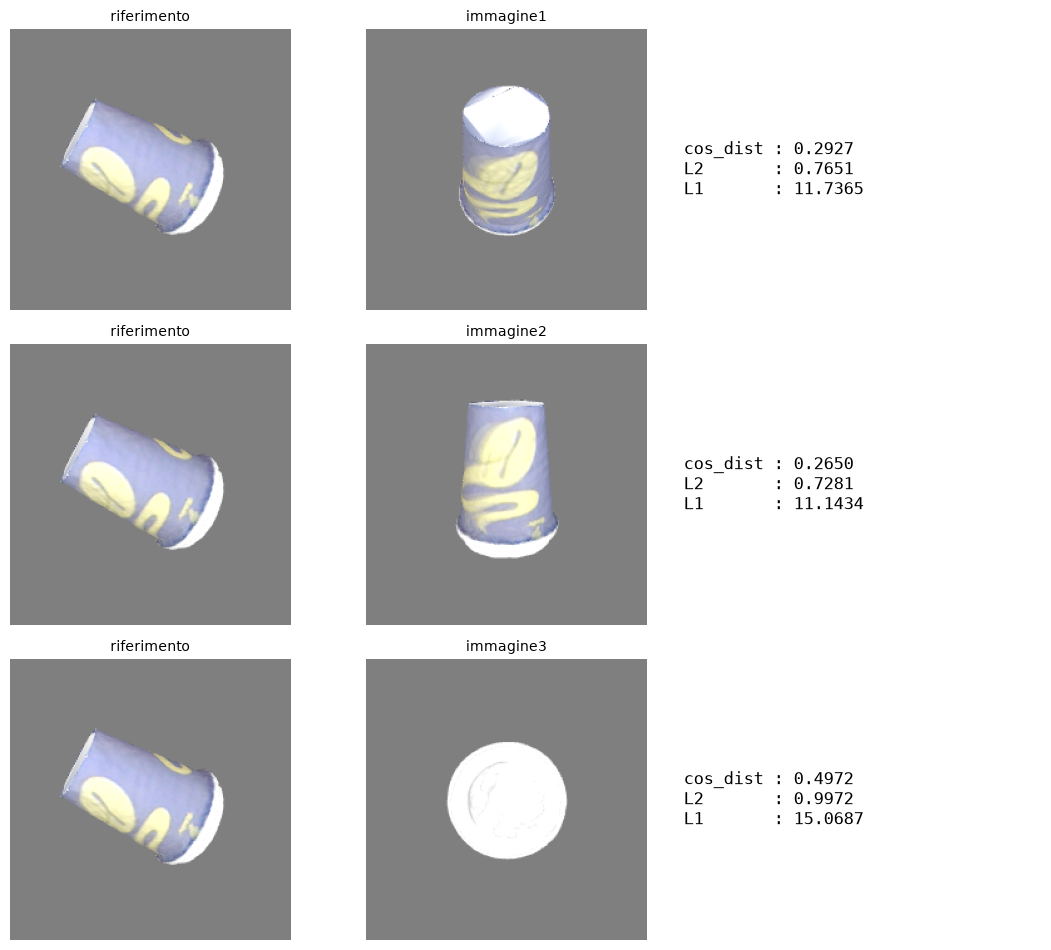

In [34]:
def plot_comparisons(ref_img, others, labels, layers=[-1], token="cls"):
    """
    Per ogni confronto mostra: [ref | altra | metriche].
      ref_img : immagine di riferimento (PIL)
      others  : lista di immagini PIL da confrontare con ref
      labels  : lista di etichette (es. ["vicinissima", "vicina", "lontana"])
    """
    n = len(others)
    fig, axes = plt.subplots(n, 3, figsize=(11, 3.2 * n))
    if n == 1:
        axes = axes[None, :]          # uniforma la forma quando c'è un solo confronto

    for row, (img, lab) in enumerate(zip(others, labels)):
        d = compare(ref_img, img, layers=layers, token=token)

        axes[row, 0].imshow(ref_img)
        axes[row, 0].set_title("riferimento", fontsize=10)
        axes[row, 0].axis("off")

        axes[row, 1].imshow(img)
        axes[row, 1].set_title(lab, fontsize=10)
        axes[row, 1].axis("off")

        txt = (f"cos_dist : {d['cos_dist']:.4f}\n"
               f"L2       : {d['l2']:.4f}\n"
               f"L1       : {d['l1']:.4f}")
        axes[row, 2].text(0.0, 0.5, txt, fontsize=12, family="monospace",
                          va="center", ha="left")
        axes[row, 2].axis("off")

    plt.tight_layout()
    plt.show()


# --- uso: ordina dal più vicino al più lontano ---
plot_comparisons(
    ref_img = img0,
    others  = [img_nearer, img_near, img_far],
    labels  = ["immagine1", "immagine2", "immagine3"],
)

# COMPARISON Last LAYER with CLASS TOKEN

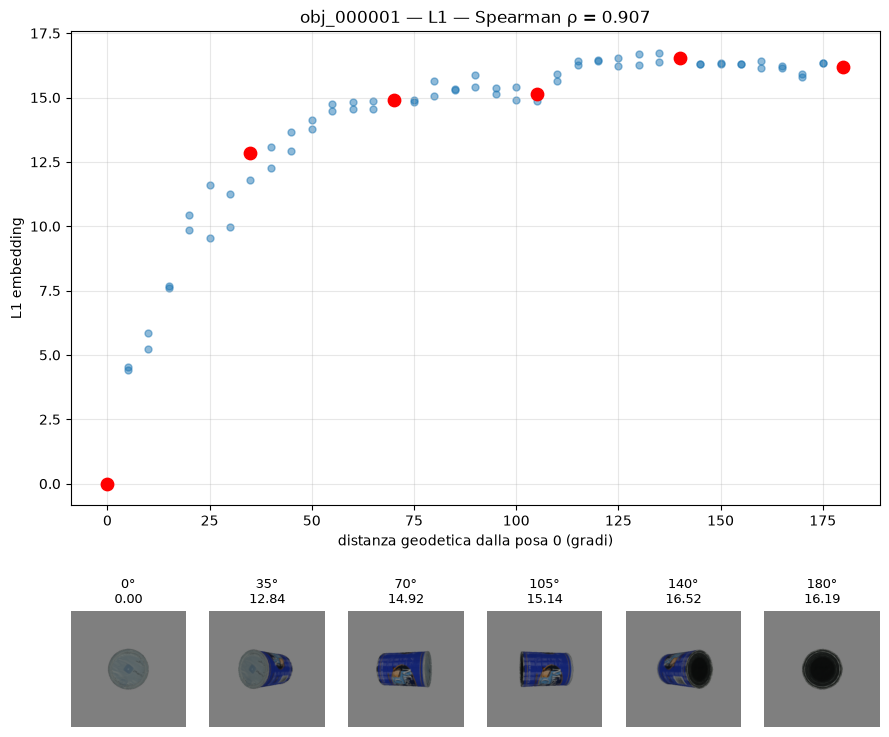

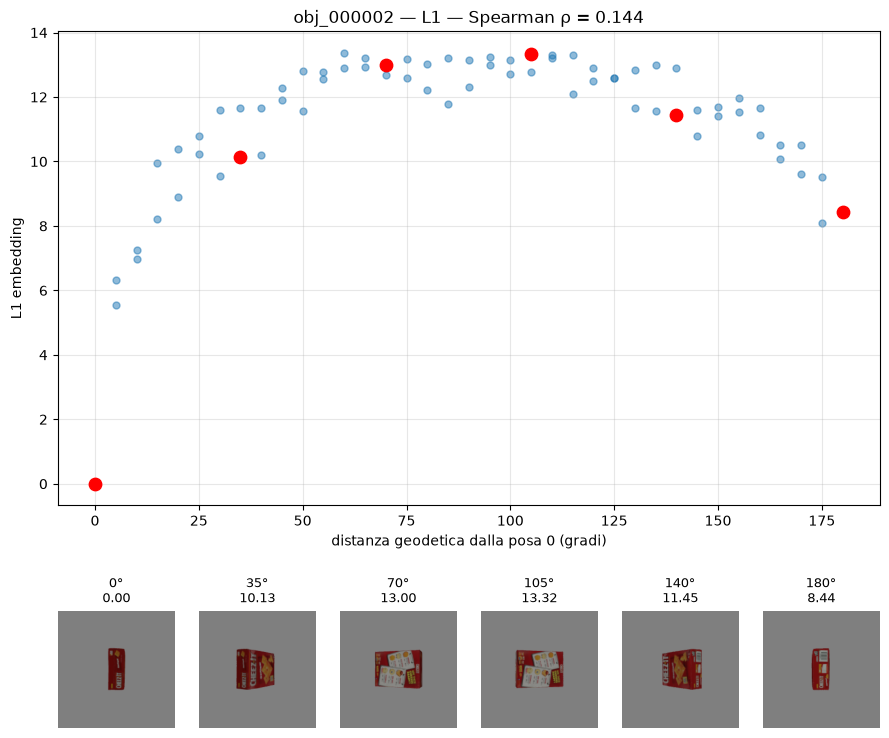

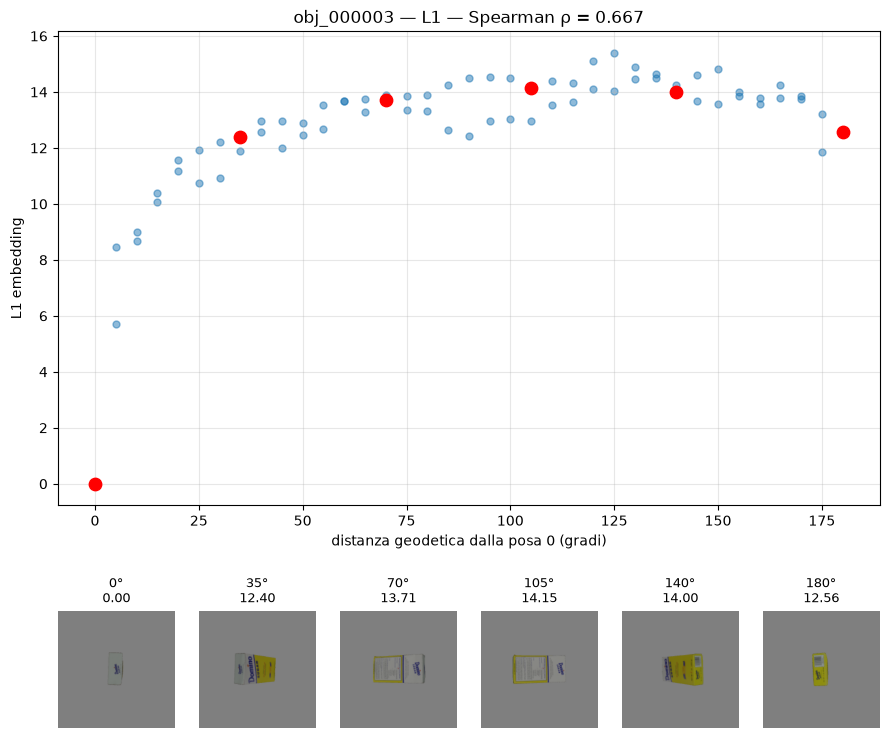

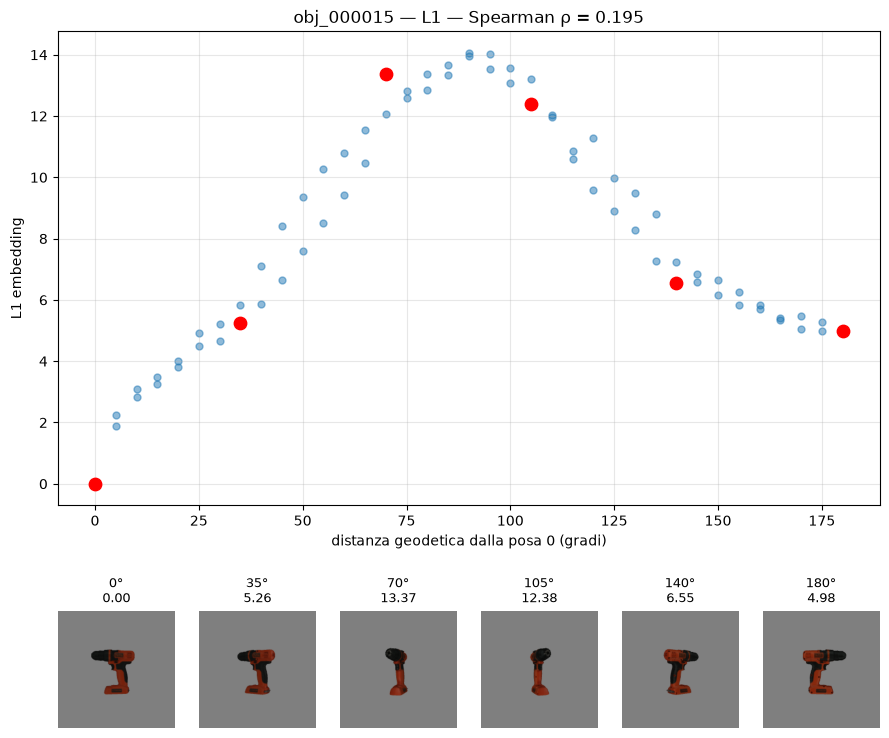

In [35]:
import pandas as pd
from scipy.spatial.transform import Rotation
from scipy.stats import spearmanr

def plot_object(obj_name, dataset="ycbv", layers=[-1], token="cls", metric="cos_dist"):
    # 1. leggi il CSV e filtra l'oggetto
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    assert len(df) > 0, f"nessuna riga per {obj_name}"

    # 2. ricostruisci le rotazioni
    r_cols = [f"r{a}{b}" for a in range(3) for b in range(3)]
    R_all = Rotation.from_matrix(df[r_cols].values.reshape(-1, 3, 3))

    # 3. riferimento = prima riga
    R_ref = R_all[0]
    e_ref = extract_features(Image.open(RENDERS / df.loc[0, "image"]).convert("RGB"),
                             layers=layers, token=token)

    # 4. angoli + distanza (secondo la metrica scelta)
    angles, dists = [], []
    for i in range(len(df)):
        ang = (R_ref.inv() * R_all[i]).magnitude() * 180 / np.pi
        e = extract_features(Image.open(RENDERS / df.loc[i, "image"]).convert("RGB"),
                             layers=layers, token=token)
        if metric == "cos_dist":
            d = 1.0 - F.cosine_similarity(e_ref, e, dim=0).item()
        elif metric == "L2":
            d = torch.norm(e_ref - e).item()
        elif metric == "L1":
            d = torch.abs(e_ref - e).sum().item()
        else:
            raise ValueError(metric)
        dists.append(d)
        angles.append(ang)
    angles, dists = np.array(angles), np.array(dists)
    rho, _ = spearmanr(angles, dists)

    # 6 viste equispaziate lungo l'asse degli angoli
    order = np.argsort(angles)
    sel = order[np.linspace(0, len(order) - 1, 6).astype(int)]

    # --- figura: scatter sopra + 6 viste sotto ---
    fig, axes = plt.subplots(2, 1, figsize=(9, 8),
                             gridspec_kw={"height_ratios": [3, 1.4]})
    axes[0].scatter(angles, dists, s=25, alpha=0.5)
    axes[0].scatter(angles[sel], dists[sel], s=80, color="red", zorder=5)
    axes[0].set_xlabel("distanza geodetica dalla posa 0 (gradi)")
    axes[0].set_ylabel(f"{metric} embedding")
    axes[0].set_title(f"{obj_name} — {metric} — Spearman ρ = {rho:.3f}")
    axes[0].grid(alpha=0.3)

    gs = axes[1].get_subplotspec().subgridspec(1, 6)
    axes[1].remove()
    for k, idx in enumerate(sel):
        ax = fig.add_subplot(gs[0, k])
        ax.imshow(Image.open(RENDERS / df.loc[idx, "image"]).convert("RGB"))
        ax.set_title(f"{angles[idx]:.0f}°\n{dists[idx]:.2f}", fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


OBJECTS = ["obj_000001", "obj_000002", "obj_000003", "obj_000015"]
for obj in OBJECTS:
    plot_object(obj, metric="L1")     # cambia in "cos_dist" / "L2" / "L1"

# COMPARISON More LAYER(4-8-LAST) with CLASS TOKEN

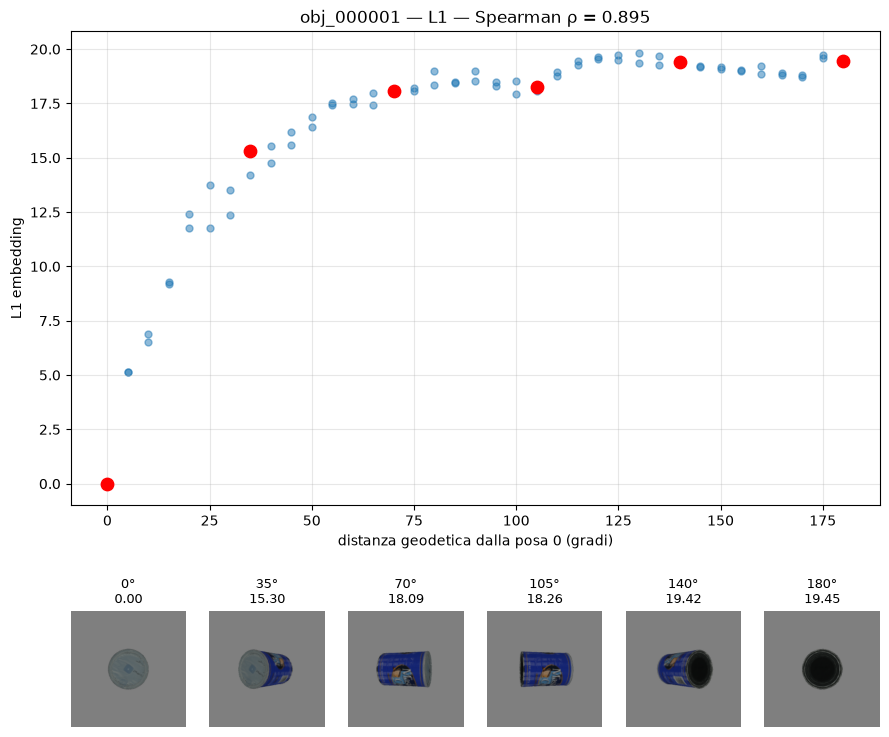

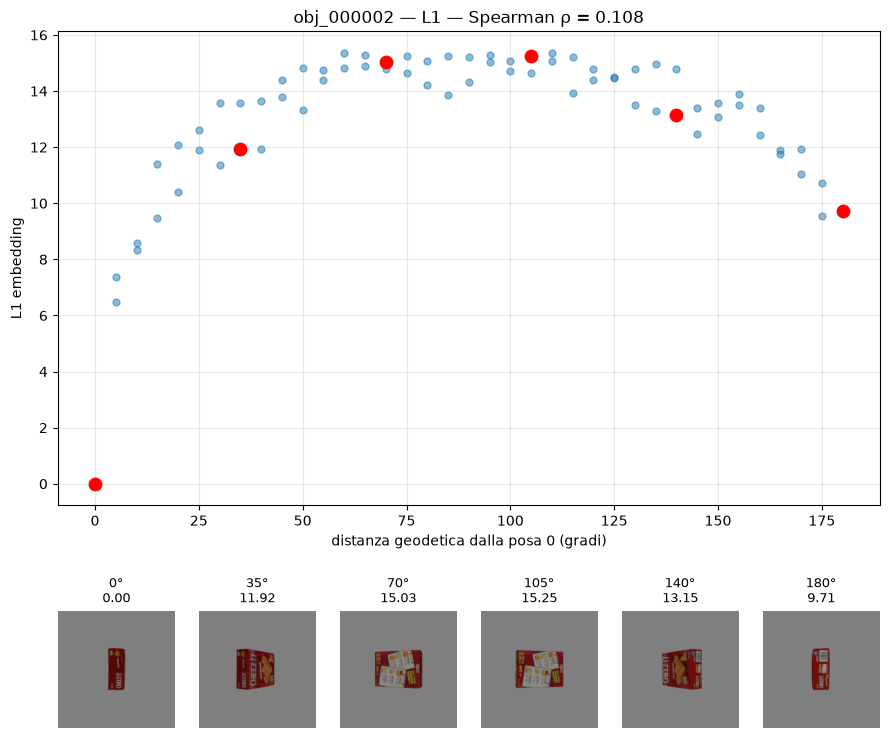

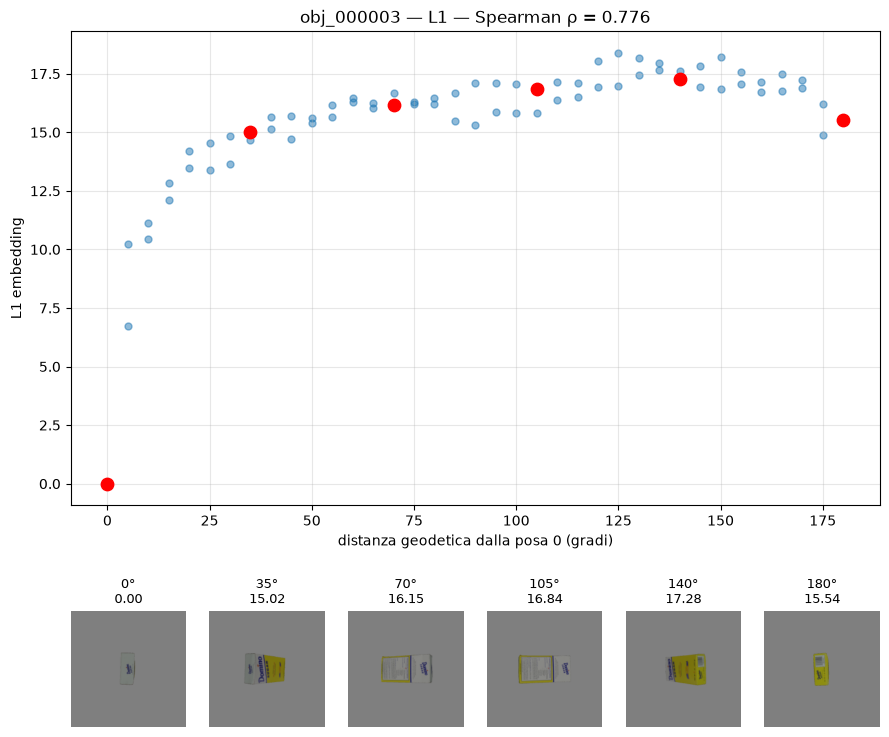

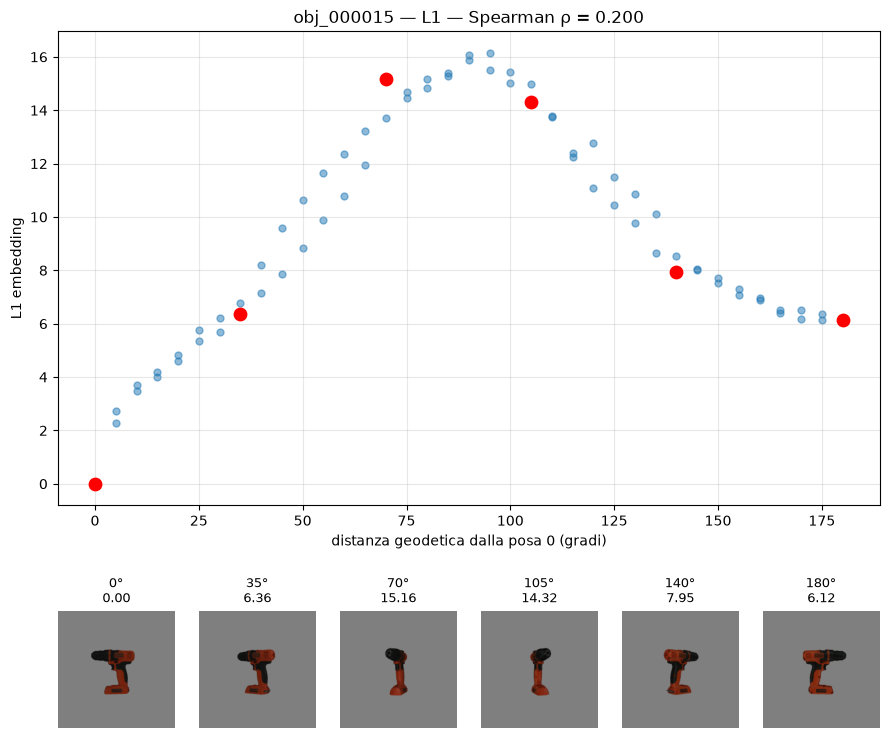

In [36]:
import pandas as pd
from scipy.spatial.transform import Rotation
from scipy.stats import spearmanr

def plot_object(obj_name, dataset="ycbv", layers=[4,8,-1], token="cls", metric="L1"):
    # 1. leggi il CSV e filtra l'oggetto
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    assert len(df) > 0, f"nessuna riga per {obj_name}"

    # 2. ricostruisci le rotazioni
    r_cols = [f"r{a}{b}" for a in range(3) for b in range(3)]
    R_all = Rotation.from_matrix(df[r_cols].values.reshape(-1, 3, 3))

    # 3. riferimento = prima riga
    R_ref = R_all[0]
    e_ref = extract_features(Image.open(RENDERS / df.loc[0, "image"]).convert("RGB"),
                             layers=layers, token=token)

    # 4. angoli + distanza (secondo la metrica scelta)
    angles, dists = [], []
    for i in range(len(df)):
        ang = (R_ref.inv() * R_all[i]).magnitude() * 180 / np.pi
        e = extract_features(Image.open(RENDERS / df.loc[i, "image"]).convert("RGB"),
                             layers=layers, token=token)
        if metric == "cos_dist":
            d = 1.0 - F.cosine_similarity(e_ref, e, dim=0).item()
        elif metric == "L2":
            d = torch.norm(e_ref - e).item()
        elif metric == "L1":
            d = torch.abs(e_ref - e).sum().item()
        else:
            raise ValueError(metric)
        dists.append(d)
        angles.append(ang)
    angles, dists = np.array(angles), np.array(dists)
    rho, _ = spearmanr(angles, dists)

    # 6 viste equispaziate lungo l'asse degli angoli
    order = np.argsort(angles)
    sel = order[np.linspace(0, len(order) - 1, 6).astype(int)]

    # --- figura: scatter sopra + 6 viste sotto ---
    fig, axes = plt.subplots(2, 1, figsize=(9, 8),
                             gridspec_kw={"height_ratios": [3, 1.4]})
    axes[0].scatter(angles, dists, s=25, alpha=0.5)
    axes[0].scatter(angles[sel], dists[sel], s=80, color="red", zorder=5)
    axes[0].set_xlabel("distanza geodetica dalla posa 0 (gradi)")
    axes[0].set_ylabel(f"{metric} embedding")
    axes[0].set_title(f"{obj_name} — {metric} — Spearman ρ = {rho:.3f}")
    axes[0].grid(alpha=0.3)

    gs = axes[1].get_subplotspec().subgridspec(1, 6)
    axes[1].remove()
    for k, idx in enumerate(sel):
        ax = fig.add_subplot(gs[0, k])
        ax.imshow(Image.open(RENDERS / df.loc[idx, "image"]).convert("RGB"))
        ax.set_title(f"{angles[idx]:.0f}°\n{dists[idx]:.2f}", fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


OBJECTS = ["obj_000001", "obj_000002", "obj_000003", "obj_000015"]
for obj in OBJECTS:
    plot_object(obj, metric="L1")     

# COMPARISON WITH ROTATION y Last LAYER with PatchToken

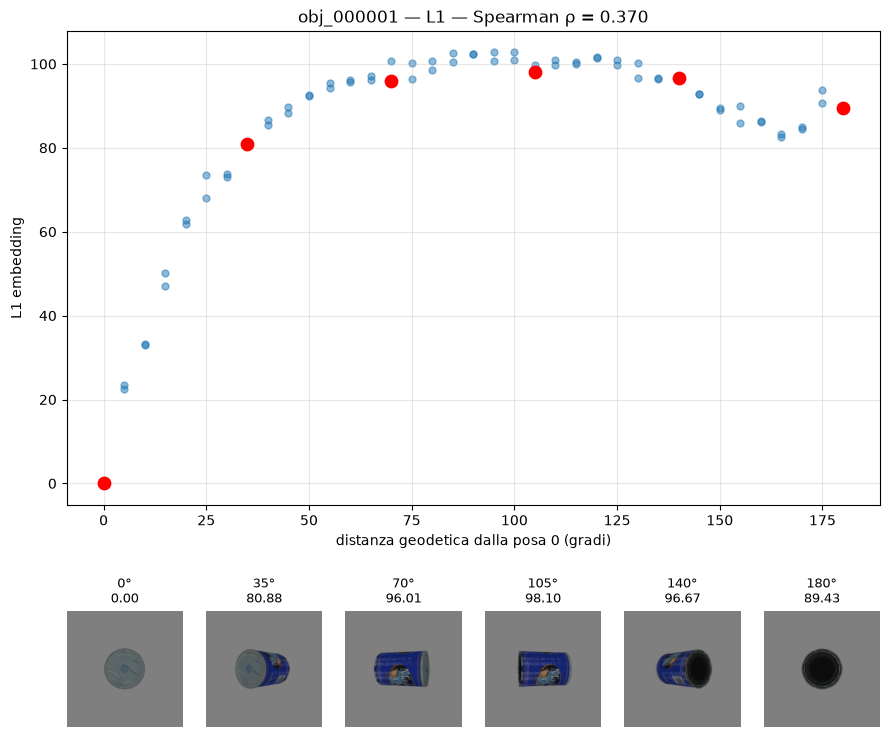

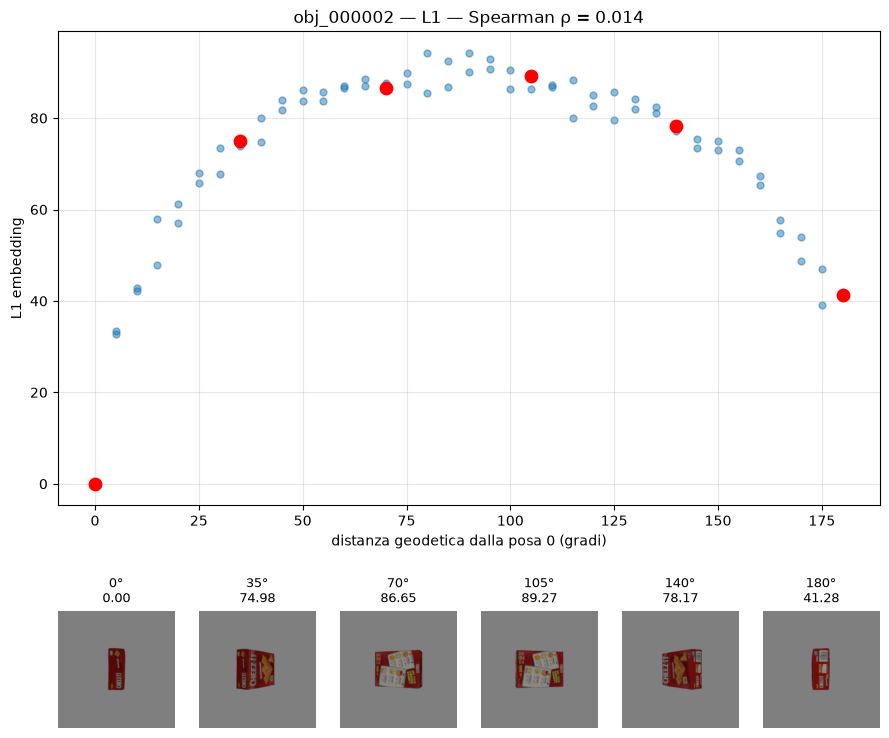

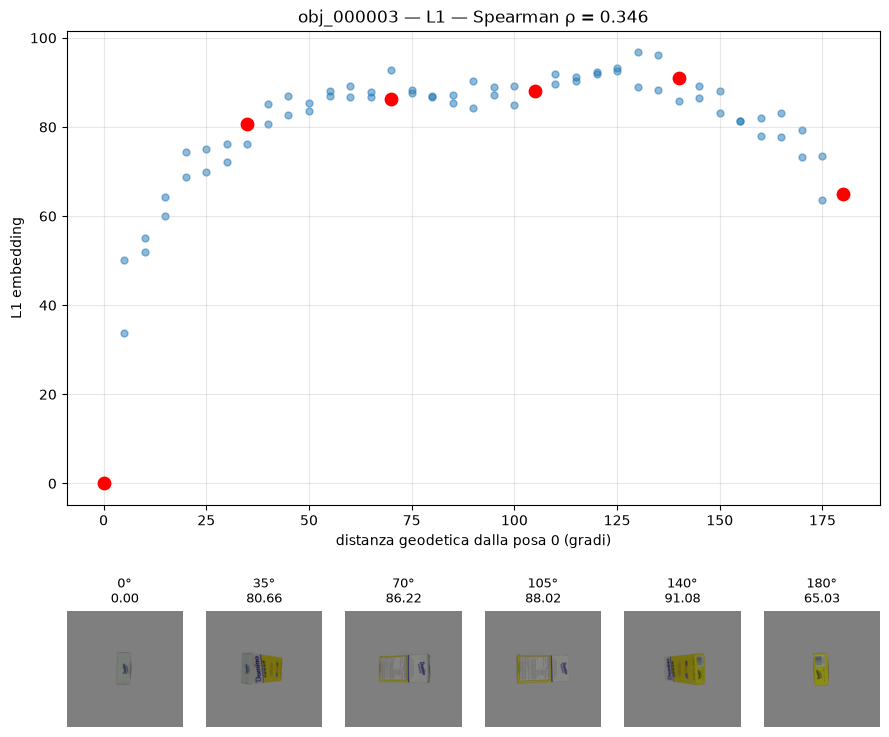

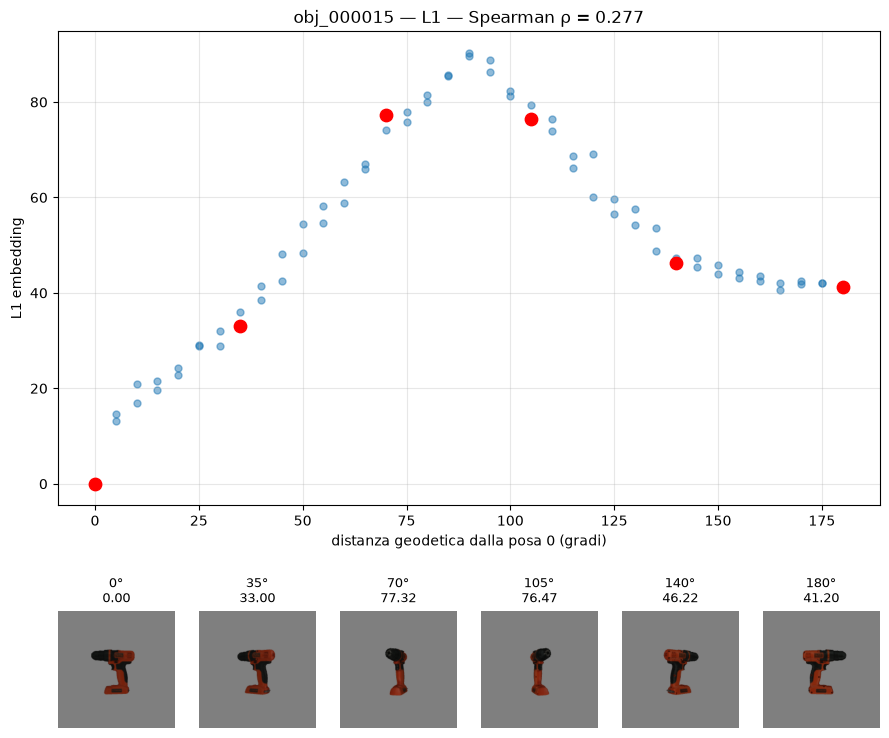

In [37]:
import pandas as pd
from scipy.spatial.transform import Rotation
from scipy.stats import spearmanr

def plot_object(obj_name, dataset="ycbv", layers=[-1], token="ptc", metric="L1"):
    # 1. leggi il CSV e filtra l'oggetto
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    assert len(df) > 0, f"nessuna riga per {obj_name}"

    # 2. ricostruisci le rotazioni
    r_cols = [f"r{a}{b}" for a in range(3) for b in range(3)]
    R_all = Rotation.from_matrix(df[r_cols].values.reshape(-1, 3, 3))

    # 3. riferimento = prima riga
    R_ref = R_all[0]
    e_ref = extract_features(Image.open(RENDERS / df.loc[0, "image"]).convert("RGB"),
                             layers=layers, token=token)

    # 4. angoli + distanza (secondo la metrica scelta)
    angles, dists = [], []
    for i in range(len(df)):
        ang = (R_ref.inv() * R_all[i]).magnitude() * 180 / np.pi
        e = extract_features(Image.open(RENDERS / df.loc[i, "image"]).convert("RGB"),
                             layers=layers, token=token)
        if metric == "cos_dist":
            d = 1.0 - F.cosine_similarity(e_ref, e, dim=0).item()
        elif metric == "L2":
            d = torch.norm(e_ref - e).item()
        elif metric == "L1":
            d = torch.abs(e_ref - e).sum().item()
        else:
            raise ValueError(metric)
        dists.append(d)
        angles.append(ang)
    angles, dists = np.array(angles), np.array(dists)
    rho, _ = spearmanr(angles, dists)

    # 6 viste equispaziate lungo l'asse degli angoli
    order = np.argsort(angles)
    sel = order[np.linspace(0, len(order) - 1, 6).astype(int)]

    # --- figura: scatter sopra + 6 viste sotto ---
    fig, axes = plt.subplots(2, 1, figsize=(9, 8),
                             gridspec_kw={"height_ratios": [3, 1.4]})
    axes[0].scatter(angles, dists, s=25, alpha=0.5)
    axes[0].scatter(angles[sel], dists[sel], s=80, color="red", zorder=5)
    axes[0].set_xlabel("distanza geodetica dalla posa 0 (gradi)")
    axes[0].set_ylabel(f"{metric} embedding")
    axes[0].set_title(f"{obj_name} — {metric} — Spearman ρ = {rho:.3f}")
    axes[0].grid(alpha=0.3)

    gs = axes[1].get_subplotspec().subgridspec(1, 6)
    axes[1].remove()
    for k, idx in enumerate(sel):
        ax = fig.add_subplot(gs[0, k])
        ax.imshow(Image.open(RENDERS / df.loc[idx, "image"]).convert("RGB"))
        ax.set_title(f"{angles[idx]:.0f}°\n{dists[idx]:.2f}", fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


OBJECTS = ["obj_000001", "obj_000002", "obj_000003", "obj_000015"]
for obj in OBJECTS:
    plot_object(obj, metric="L1")     

# COMPARISON PATCH TOKEN WITH MORE LAYERS (4-8- Last)

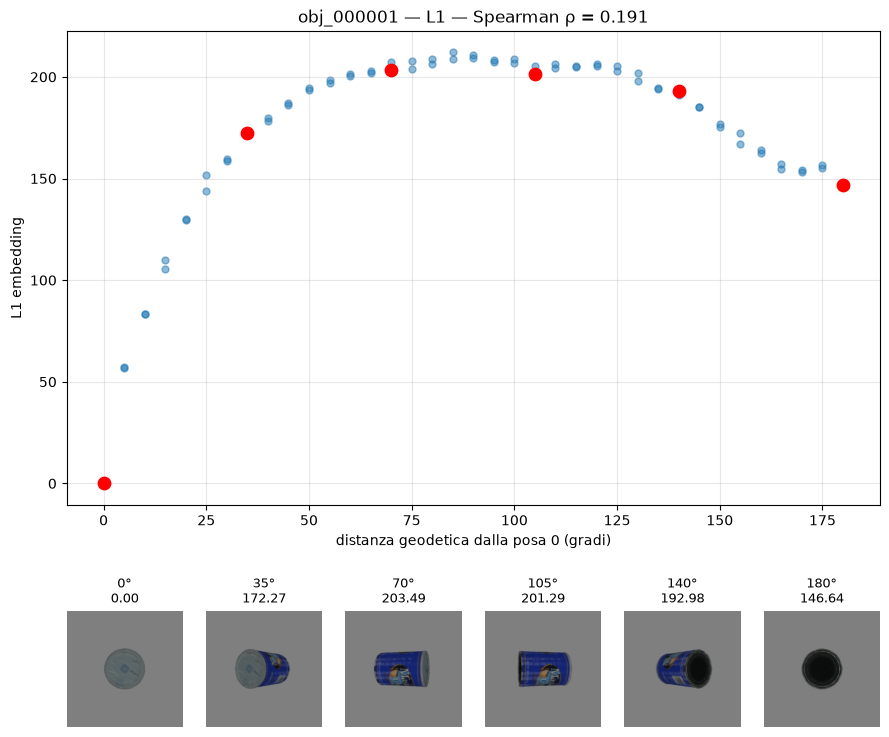

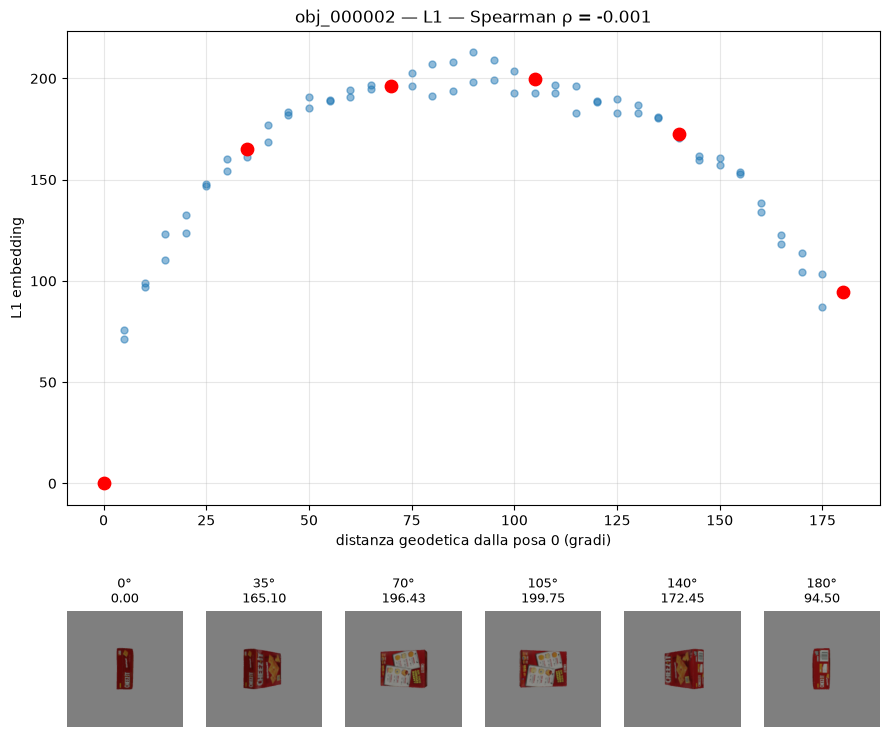

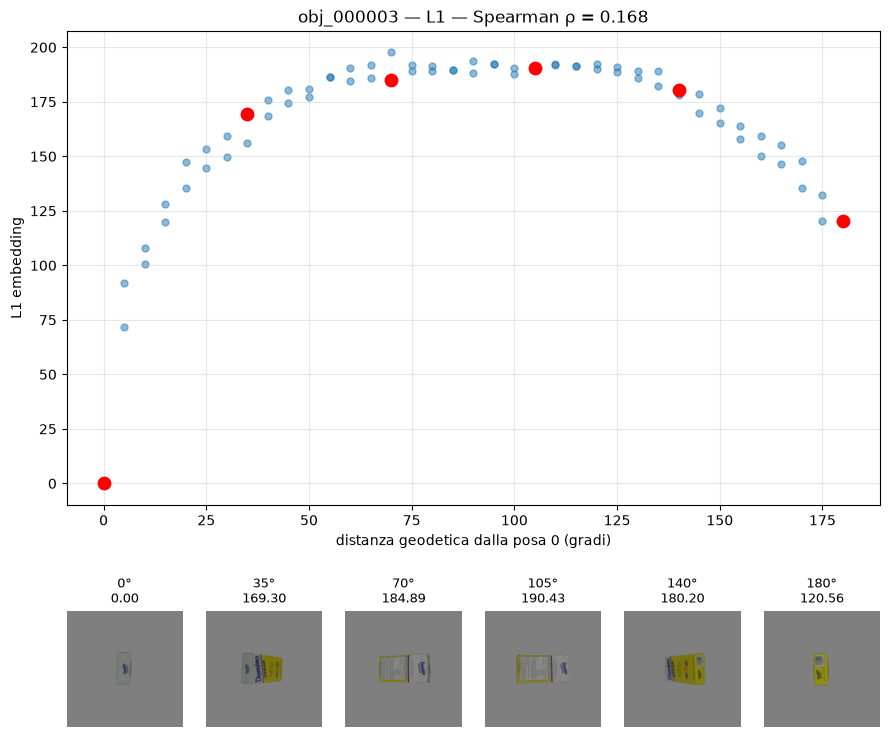

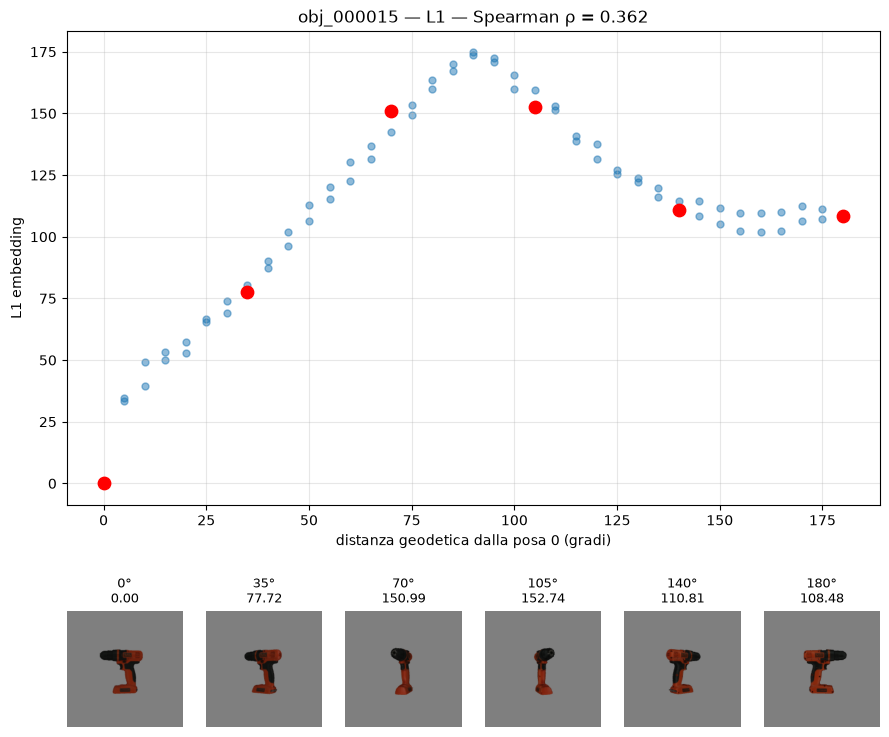

In [38]:
import pandas as pd
from scipy.spatial.transform import Rotation
from scipy.stats import spearmanr

def plot_object(obj_name, dataset="ycbv", layers=[4,8,-1], token="ptc", metric="cos_dist"):
    # 1. leggi il CSV e filtra l'oggetto
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    assert len(df) > 0, f"nessuna riga per {obj_name}"

    # 2. ricostruisci le rotazioni
    r_cols = [f"r{a}{b}" for a in range(3) for b in range(3)]
    R_all = Rotation.from_matrix(df[r_cols].values.reshape(-1, 3, 3))

    # 3. riferimento = prima riga
    R_ref = R_all[0]
    e_ref = extract_features(Image.open(RENDERS / df.loc[0, "image"]).convert("RGB"),
                             layers=layers, token=token)

    # 4. angoli + distanza (secondo la metrica scelta)
    angles, dists = [], []
    for i in range(len(df)):
        ang = (R_ref.inv() * R_all[i]).magnitude() * 180 / np.pi
        e = extract_features(Image.open(RENDERS / df.loc[i, "image"]).convert("RGB"),
                             layers=layers, token=token)
        if metric == "cos_dist":
            d = 1.0 - F.cosine_similarity(e_ref, e, dim=0).item()
        elif metric == "L2":
            d = torch.norm(e_ref - e).item()
        elif metric == "L1":
            d = torch.abs(e_ref - e).sum().item()
        else:
            raise ValueError(metric)
        dists.append(d)
        angles.append(ang)
    angles, dists = np.array(angles), np.array(dists)
    rho, _ = spearmanr(angles, dists)

    # 6 viste equispaziate lungo l'asse degli angoli
    order = np.argsort(angles)
    sel = order[np.linspace(0, len(order) - 1, 6).astype(int)]

    # --- figura: scatter sopra + 6 viste sotto ---
    fig, axes = plt.subplots(2, 1, figsize=(9, 8),
                             gridspec_kw={"height_ratios": [3, 1.4]})
    axes[0].scatter(angles, dists, s=25, alpha=0.5)
    axes[0].scatter(angles[sel], dists[sel], s=80, color="red", zorder=5)
    axes[0].set_xlabel("distanza geodetica dalla posa 0 (gradi)")
    axes[0].set_ylabel(f"{metric} embedding")
    axes[0].set_title(f"{obj_name} — {metric} — Spearman ρ = {rho:.3f}")
    axes[0].grid(alpha=0.3)

    gs = axes[1].get_subplotspec().subgridspec(1, 6)
    axes[1].remove()
    for k, idx in enumerate(sel):
        ax = fig.add_subplot(gs[0, k])
        ax.imshow(Image.open(RENDERS / df.loc[idx, "image"]).convert("RGB"))
        ax.set_title(f"{angles[idx]:.0f}°\n{dists[idx]:.2f}", fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


OBJECTS = ["obj_000001", "obj_000002", "obj_000003", "obj_000015"]
for obj in OBJECTS:
    plot_object(obj, metric="L1")     

# COMPARISON POOLED PATCH TOKEN Last Layer 

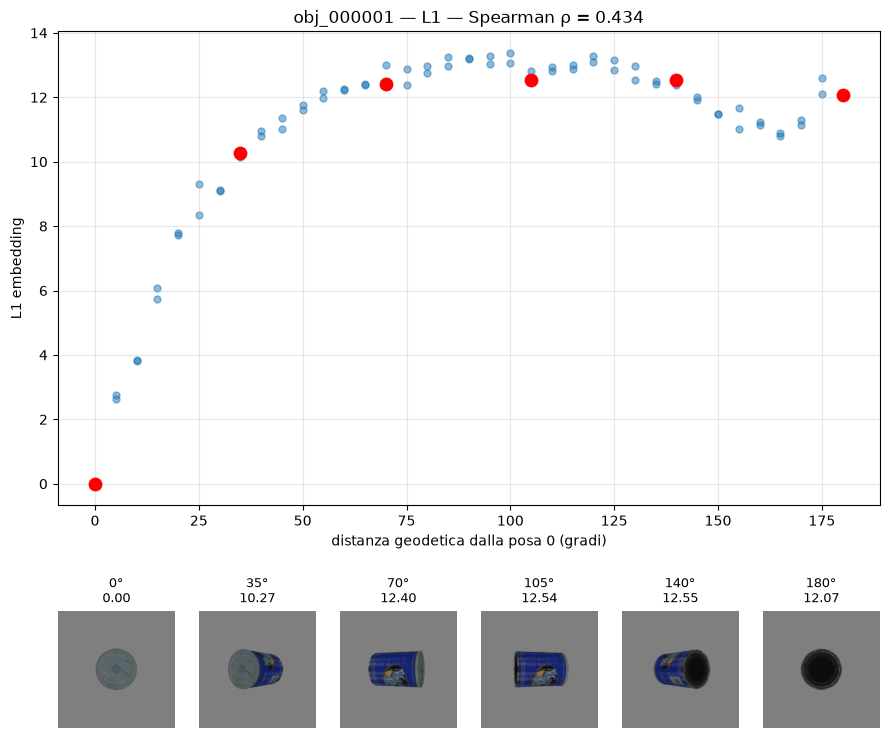

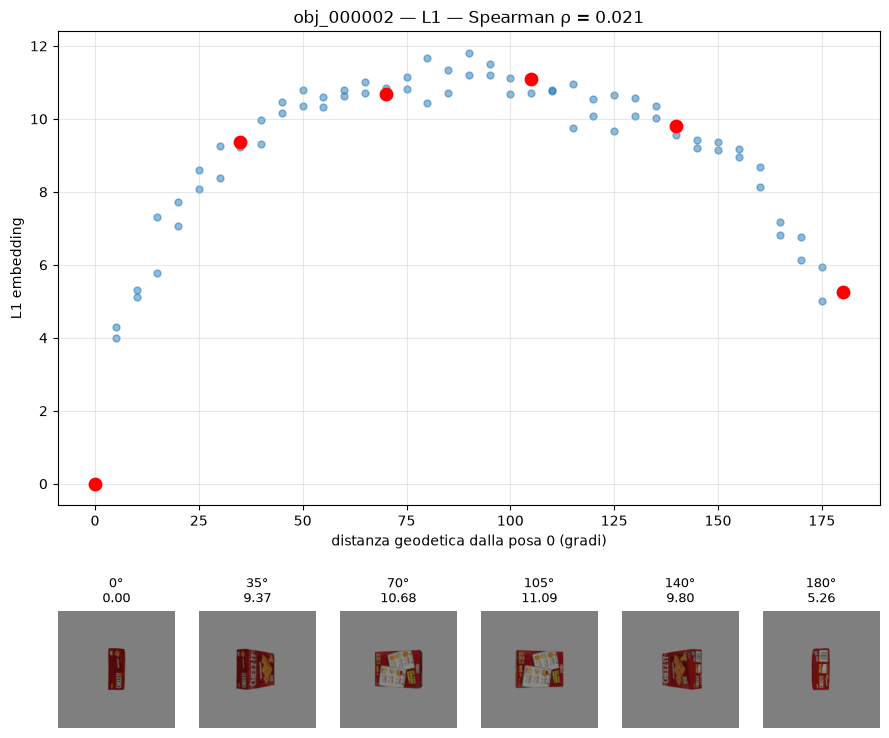

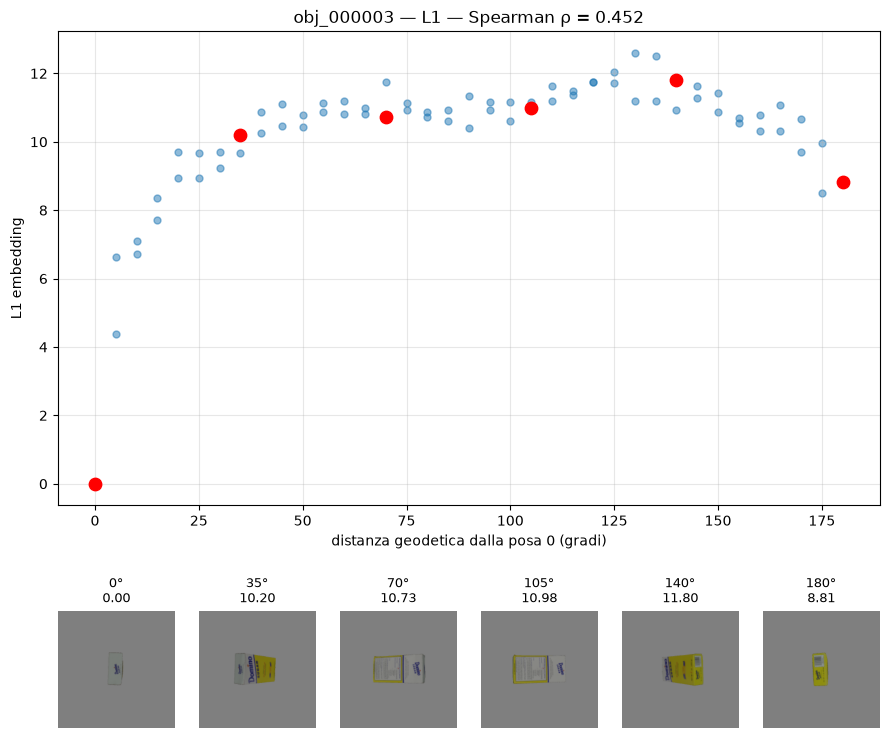

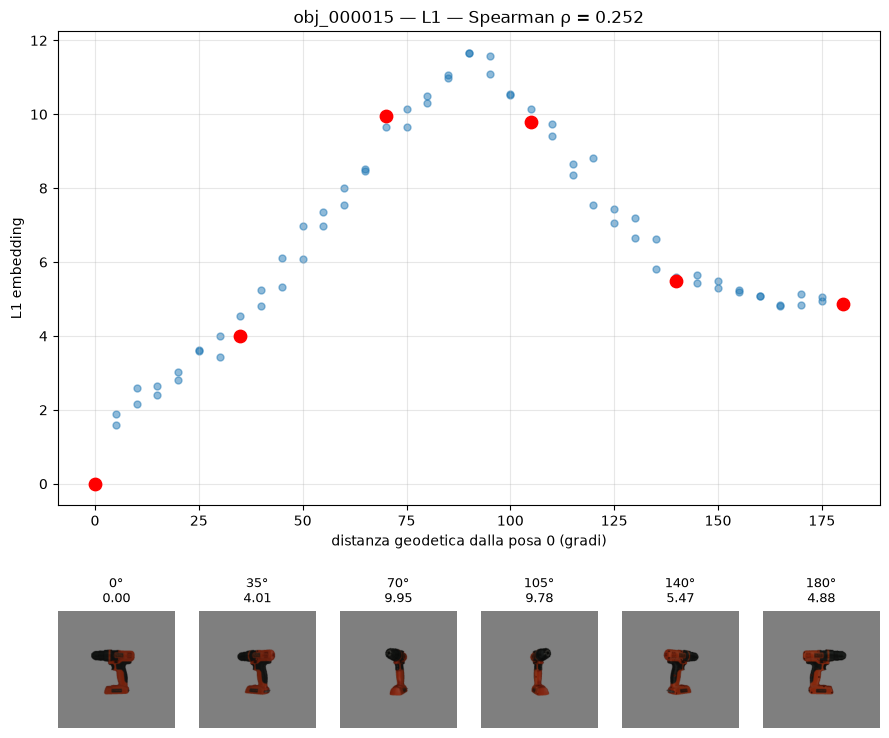

In [39]:
import pandas as pd
from scipy.spatial.transform import Rotation
from scipy.stats import spearmanr

def plot_object(obj_name, dataset="ycbv", layers=[-1], token="pool", metric="cos_dist"):
    # 1. leggi il CSV e filtra l'oggetto
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    assert len(df) > 0, f"nessuna riga per {obj_name}"

    # 2. ricostruisci le rotazioni
    r_cols = [f"r{a}{b}" for a in range(3) for b in range(3)]
    R_all = Rotation.from_matrix(df[r_cols].values.reshape(-1, 3, 3))

    # 3. riferimento = prima riga
    R_ref = R_all[0]
    e_ref = extract_features(Image.open(RENDERS / df.loc[0, "image"]).convert("RGB"),
                             layers=layers, token=token)

    # 4. angoli + distanza (secondo la metrica scelta)
    angles, dists = [], []
    for i in range(len(df)):
        ang = (R_ref.inv() * R_all[i]).magnitude() * 180 / np.pi
        e = extract_features(Image.open(RENDERS / df.loc[i, "image"]).convert("RGB"),
                             layers=layers, token=token)
        if metric == "cos_dist":
            d = 1.0 - F.cosine_similarity(e_ref, e, dim=0).item()
        elif metric == "L2":
            d = torch.norm(e_ref - e).item()
        elif metric == "L1":
            d = torch.abs(e_ref - e).sum().item()
        else:
            raise ValueError(metric)
        dists.append(d)
        angles.append(ang)
    angles, dists = np.array(angles), np.array(dists)
    rho, _ = spearmanr(angles, dists)

    # 6 viste equispaziate lungo l'asse degli angoli
    order = np.argsort(angles)
    sel = order[np.linspace(0, len(order) - 1, 6).astype(int)]

    # --- figura: scatter sopra + 6 viste sotto ---
    fig, axes = plt.subplots(2, 1, figsize=(9, 8),
                             gridspec_kw={"height_ratios": [3, 1.4]})
    axes[0].scatter(angles, dists, s=25, alpha=0.5)
    axes[0].scatter(angles[sel], dists[sel], s=80, color="red", zorder=5)
    axes[0].set_xlabel("distanza geodetica dalla posa 0 (gradi)")
    axes[0].set_ylabel(f"{metric} embedding")
    axes[0].set_title(f"{obj_name} — {metric} — Spearman ρ = {rho:.3f}")
    axes[0].grid(alpha=0.3)

    gs = axes[1].get_subplotspec().subgridspec(1, 6)
    axes[1].remove()
    for k, idx in enumerate(sel):
        ax = fig.add_subplot(gs[0, k])
        ax.imshow(Image.open(RENDERS / df.loc[idx, "image"]).convert("RGB"))
        ax.set_title(f"{angles[idx]:.0f}°\n{dists[idx]:.2f}", fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


OBJECTS = ["obj_000001", "obj_000002", "obj_000003", "obj_000015"]
for obj in OBJECTS:
    plot_object(obj, metric="L1")     

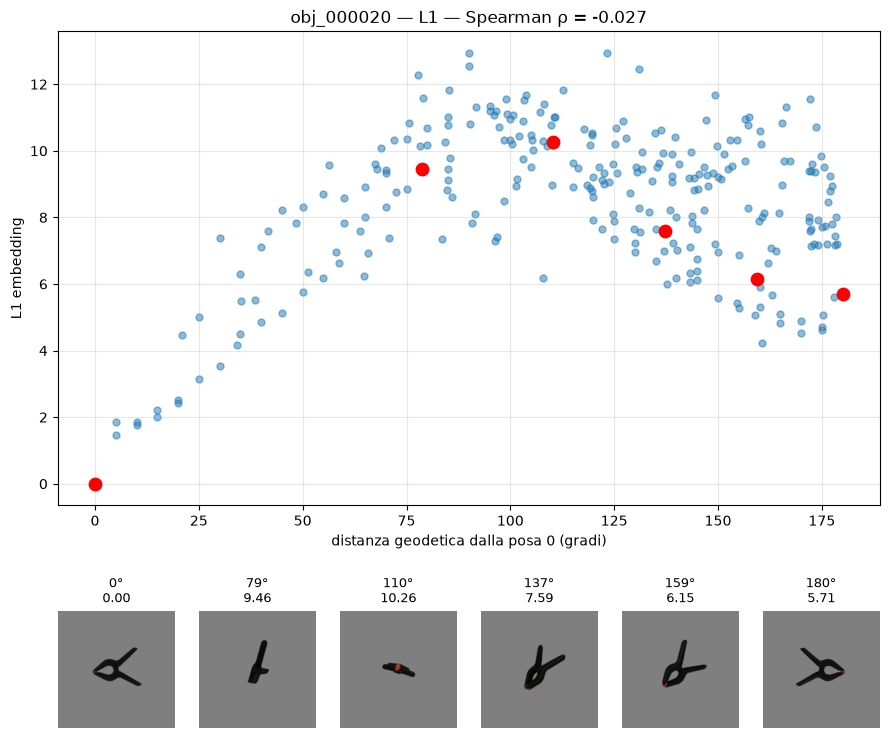

In [40]:
import pandas as pd
from scipy.spatial.transform import Rotation
from scipy.stats import spearmanr

def plot_object(obj_name, dataset="ycbv", layers=[-1], token="pool", metric="cos_dist"):
    # 1. leggi il CSV e filtra l'oggetto
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    assert len(df) > 0, f"nessuna riga per {obj_name}"

    # 2. ricostruisci le rotazioni
    r_cols = [f"r{a}{b}" for a in range(3) for b in range(3)]
    R_all = Rotation.from_matrix(df[r_cols].values.reshape(-1, 3, 3))

    # 3. riferimento = prima riga
    R_ref = R_all[0]
    e_ref = extract_features(Image.open(RENDERS / df.loc[0, "image"]).convert("RGB"),
                             layers=layers, token=token)

    # 4. angoli + distanza (secondo la metrica scelta)
    angles, dists = [], []
    for i in range(len(df)):
        ang = (R_ref.inv() * R_all[i]).magnitude() * 180 / np.pi
        e = extract_features(Image.open(RENDERS / df.loc[i, "image"]).convert("RGB"),
                             layers=layers, token=token)
        if metric == "cos_dist":
            d = 1.0 - F.cosine_similarity(e_ref, e, dim=0).item()
        elif metric == "L2":
            d = torch.norm(e_ref - e).item()
        elif metric == "L1":
            d = torch.abs(e_ref - e).sum().item()
        else:
            raise ValueError(metric)
        dists.append(d)
        angles.append(ang)
    angles, dists = np.array(angles), np.array(dists)
    rho, _ = spearmanr(angles, dists)

    # 6 viste equispaziate lungo l'asse degli angoli
    order = np.argsort(angles)
    sel = order[np.linspace(0, len(order) - 1, 6).astype(int)]

    # --- figura: scatter sopra + 6 viste sotto ---
    fig, axes = plt.subplots(2, 1, figsize=(9, 8),
                             gridspec_kw={"height_ratios": [3, 1.4]})
    axes[0].scatter(angles, dists, s=25, alpha=0.5)
    axes[0].scatter(angles[sel], dists[sel], s=80, color="red", zorder=5)
    axes[0].set_xlabel("distanza geodetica dalla posa 0 (gradi)")
    axes[0].set_ylabel(f"{metric} embedding")
    axes[0].set_title(f"{obj_name} — {metric} — Spearman ρ = {rho:.3f}")
    axes[0].grid(alpha=0.3)

    gs = axes[1].get_subplotspec().subgridspec(1, 6)
    axes[1].remove()
    for k, idx in enumerate(sel):
        ax = fig.add_subplot(gs[0, k])
        ax.imshow(Image.open(RENDERS / df.loc[idx, "image"]).convert("RGB"))
        ax.set_title(f"{angles[idx]:.0f}°\n{dists[idx]:.2f}", fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


OBJECTS = ["obj_000020"]#, "obj_000002", "obj_000003", "obj_000015"]
for obj in OBJECTS:
    plot_object(obj, metric="L1")     

# MA MI PIACE LA GRIGLI FISSA COSI ? 


In [41]:
import torch.nn.functional as F

@torch.no_grad()
def extract_features2(img, layers=[-1], token="pool", grid=2,
                     norm_mode="global", normalize=True):
    """
    token="pool" -> spatial pooling su griglia grid x grid (default 2x2)
    norm_mode:
        "global" -> L2 sul descrittore finale concatenato
        "cell"   -> L2 su ogni cella PRIMA di concatenare
    """
    inputs = processor(images=img, return_tensors="pt").to(device)
    hs = model(**inputs, output_hidden_states=True).hidden_states

    parts = []
    for L in layers:
        h = hs[L][0]                              # (n_token, 768)
        if token == "cls":
            v = h[0]
        elif token == "ptc":
            v = h[5:].flatten()
        elif token == "pool":
            P = h[5:]                             # (256, 768)
            side = int(P.shape[0] ** 0.5)         # 16
            g = P.reshape(side, side, -1)         # (16, 16, 768)
            step = side // grid                   # quante patch per cella
            cells = []
            for r in range(grid):
                for c in range(grid):
                    cell = g[r*step:(r+1)*step, c*step:(c+1)*step, :].mean(dim=(0, 1))
                    if norm_mode == "cell":
                        cell = F.normalize(cell, dim=-1)
                    cells.append(cell)
            v = torch.cat(cells)                  # (grid*grid*768,)

        elif token == "hybrid":
            cls = F.normalize(h[0], dim=-1)                     # texture/semantica
            P = h[5:]
            side = int(P.shape[0] ** 0.5)
            gr = P.reshape(side, side, -1)
            step = side // grid
            cells = [gr[r*step:(r+1)*step, c*step:(c+1)*step, :].mean(dim=(0, 1))
                     for r in range(grid) for c in range(grid)]
            pool = F.normalize(torch.cat(cells), dim=-1)         # geometria
            v = torch.cat([cls, pool])                           # texture + forma

        else:
            raise ValueError(token)

        if normalize and token not in ("hybrid") and not (token == "pool" and norm_mode == "cell"):
            v = F.normalize(v, dim=-1)
        parts.append(v)
    return torch.cat(parts, dim=-1)

# verifica dimensioni
for gr in [1, 2, 3, 4]:
    d = extract_features2(Image.new("RGB", (224,224), (128,128,128)),
                         token="pool", grid=gr).shape[0]
    print(f"grid {gr}x{gr} -> {d} dim")

grid 1x1 -> 384 dim
grid 2x2 -> 1536 dim
grid 3x3 -> 3456 dim
grid 4x4 -> 6144 dim


In [42]:
def sensitivity_curve(obj_name, dataset="xyzibd", layers=[-1], token="cls",
                      grid=2, norm_mode="global"):
    """Come plot_object ma SENZA disegnare: ritorna (angles, dists)."""
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    assert len(df) > 0, f"nessuna riga per {obj_name}"

    r_cols = [f"r{a}{b}" for a in range(3) for b in range(3)]
    R_all = Rotation.from_matrix(df[r_cols].values.reshape(-1, 3, 3))
    R_ref = R_all[0]

    e_ref = extract_features2(Image.open(RENDERS / df.loc[0, "image"]).convert("RGB"),
                             layers=layers, token=token, grid=grid, norm_mode=norm_mode)

    angles, dists = [], []
    for i in range(len(df)):
        ang = (R_ref.inv() * R_all[i]).magnitude() * 180 / np.pi
        e = extract_features2(Image.open(RENDERS / df.loc[i, "image"]).convert("RGB"),
                             layers=layers, token=token, grid=grid, norm_mode=norm_mode)
        d = 1.0 - F.cosine_similarity(e_ref, e, dim=0).item()
        dists.append(d)
        angles.append(ang)

    return np.array(angles), np.array(dists)

## Test Griglia

In [43]:
df = pd.read_csv(RENDERS/"ycbv"/"gt_poses.csv").query("object=='obj_000015'").reset_index(drop=True)

img0 = Image.open(RENDERS / df.iloc[0]["image"]).convert("RGB")
img1 = Image.open(RENDERS / df.iloc[10]["image"]).convert("RGB")

for tok, kw in [("cls", {}), ("ptc", {}), ("pool", {"grid":2}), ("pool", {"grid":4})]:
    e0 = extract_features2(img0, token=tok, **kw)
    e1 = extract_features2(img1, token=tok, **kw)
    print(f"{tok:6s} {kw} -> dim {e0.shape[0]:5d}, L1 {torch.abs(e1 - e0).sum().item():.4f}")

cls    {} -> dim   384, L1 9.3455
ptc    {} -> dim 75264, L1 54.3829
pool   {'grid': 2} -> dim  1536, L1 7.0345
pool   {'grid': 4} -> dim  6144, L1 15.3183


In [44]:
for gr in [1, 2, 4, 8,16]:
    ang, d = sensitivity_curve("obj_000015", dataset="ycbv", token="pool", grid=gr, norm_mode="global")
    mask = ang <= 200
    rho = spearmanr(ang[mask], d[mask]).statistic
    print(f"grid {gr} -> dim {gr*gr*768:6d}, rho = {rho:.3f}")

grid 1 -> dim    768, rho = 0.243
grid 2 -> dim   3072, rho = 0.253
grid 4 -> dim  12288, rho = 0.259
grid 8 -> dim  49152, rho = 0.304
grid 16 -> dim 196608, rho = nan


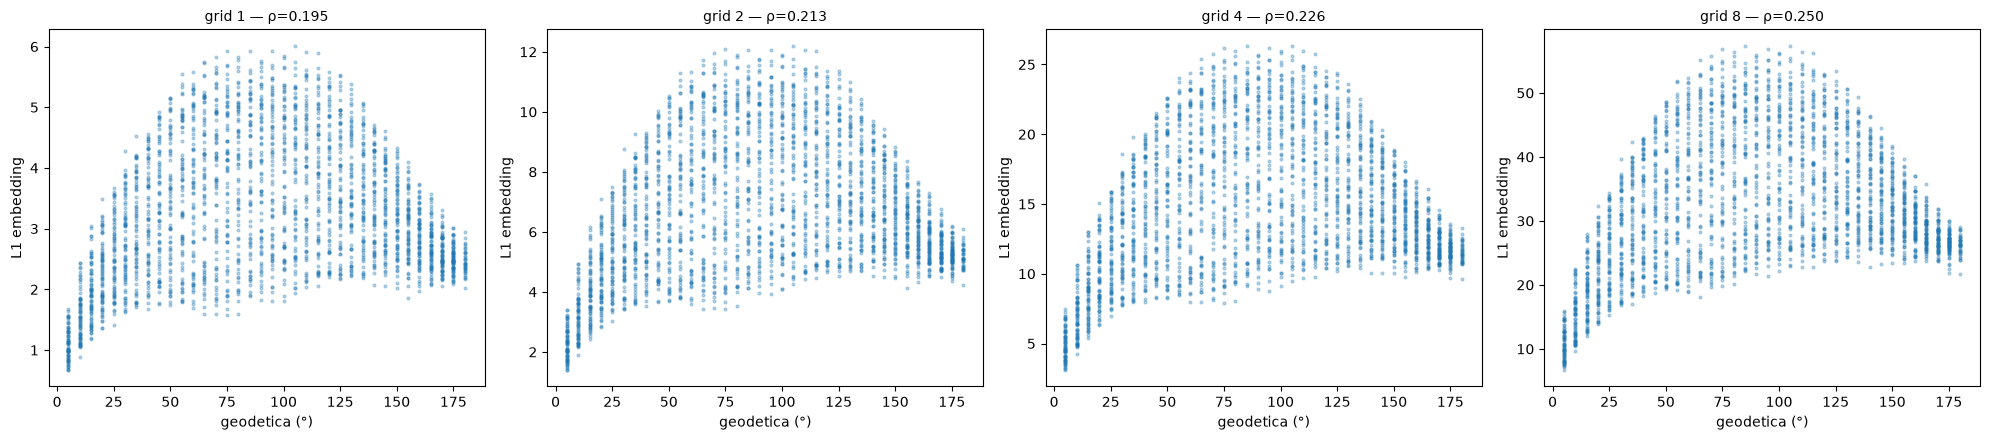

In [45]:
from itertools import combinations

def all_pairs_l1(obj_name, dataset="ycbv", token="pool", grid=2, norm_mode="global"):
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    r_cols = [f"r{a}{b}" for a in range(3) for b in range(3)]
    R_all = Rotation.from_matrix(df[r_cols].values.reshape(-1, 3, 3))

    embs = []
    for i in range(len(df)):
        e = extract_features2(Image.open(RENDERS / df.loc[i, "image"]).convert("RGB"),
                              token=token, grid=grid, norm_mode=norm_mode)
        embs.append(e)
    embs = torch.stack(embs)

    geo, l1 = [], []
    for i, j in combinations(range(len(df)), 2):
        geo.append((R_all[i].inv() * R_all[j]).magnitude() * 180/np.pi)
        l1.append(torch.abs(embs[i] - embs[j]).sum().item())     # <-- L1
    return np.array(geo), np.array(l1)


GRIDS = [1, 2, 4, 8]
fig, axes = plt.subplots(1, len(GRIDS), figsize=(5*len(GRIDS), 4.5))
for ax, gr in zip(axes, GRIDS):
    geo, l1 = all_pairs_l1("obj_000015", dataset="ycbv", grid=gr)
    rho = spearmanr(geo, l1).statistic
    ax.scatter(geo, l1, s=4, alpha=0.3)
    ax.set_title(f"grid {gr} — ρ={rho:.3f}", fontsize=10)
    ax.set_xlabel("geodetica (°)")
    ax.set_ylabel("L1 embedding")
plt.tight_layout()
plt.show()

Notato che solo con CLS token ho una miglior rappresentazione di oggetti dove le texture sono migliori, cosa al contrario con patch del trapano dove è uguale pseudo simmetrico a livello di texture ma non a livello di geometria, Proviamo con un approccio hybrid Concateniamo sia cls che patch

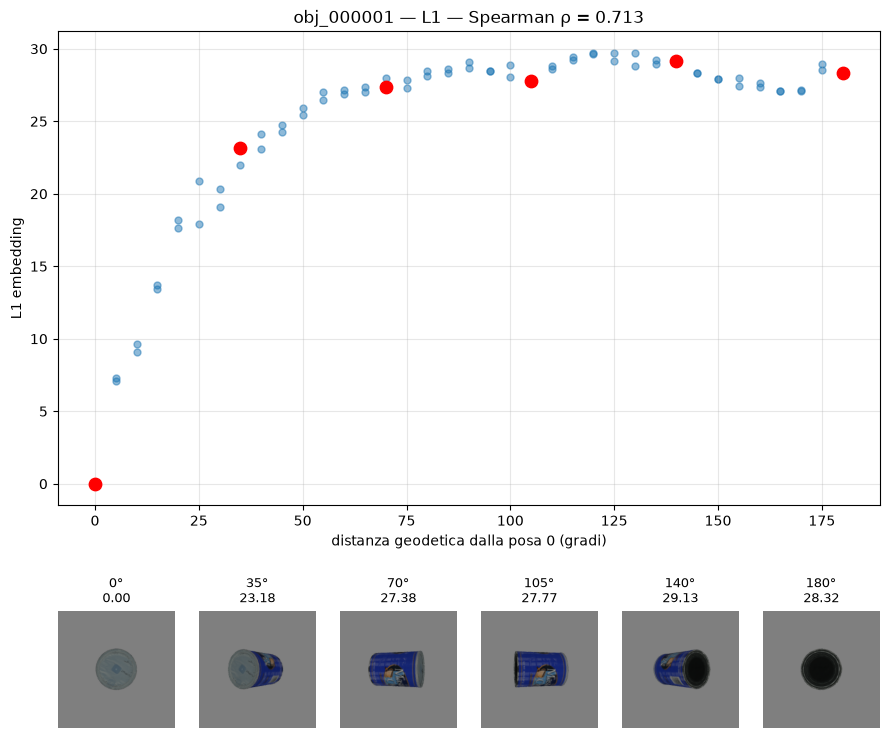

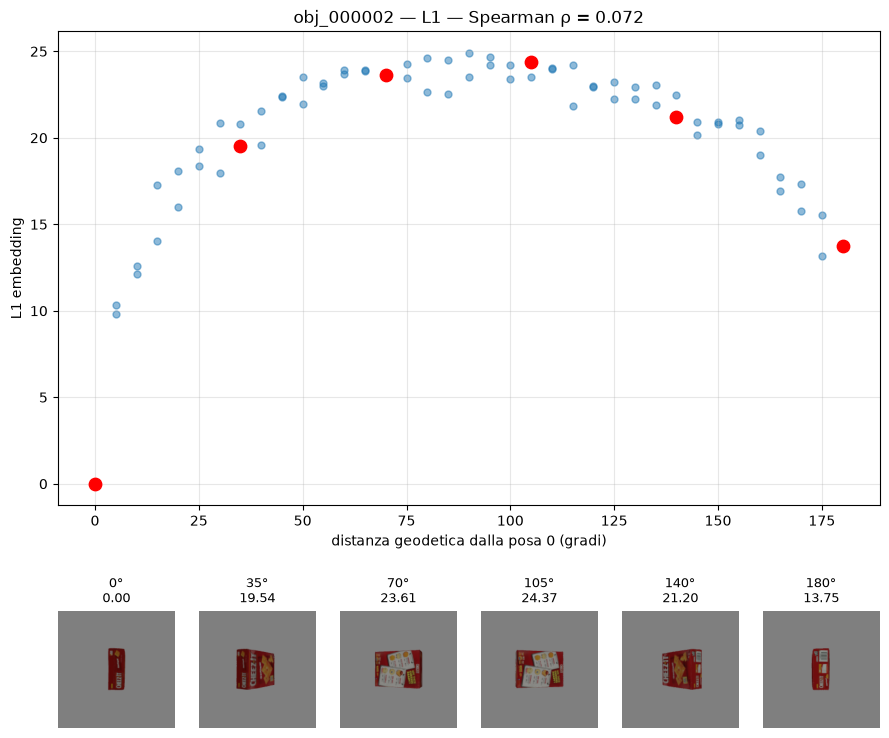

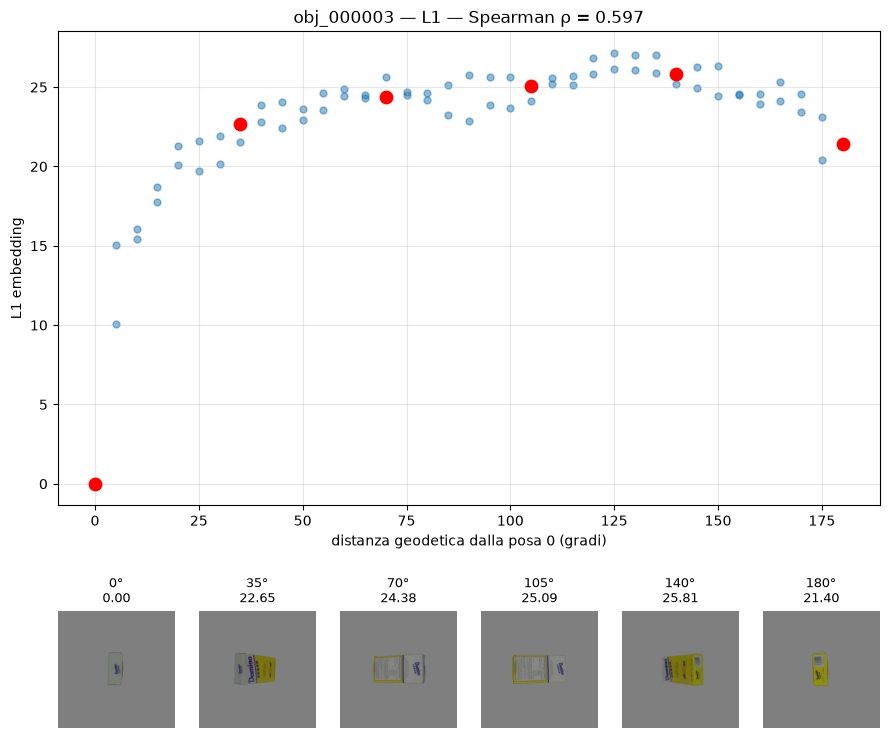

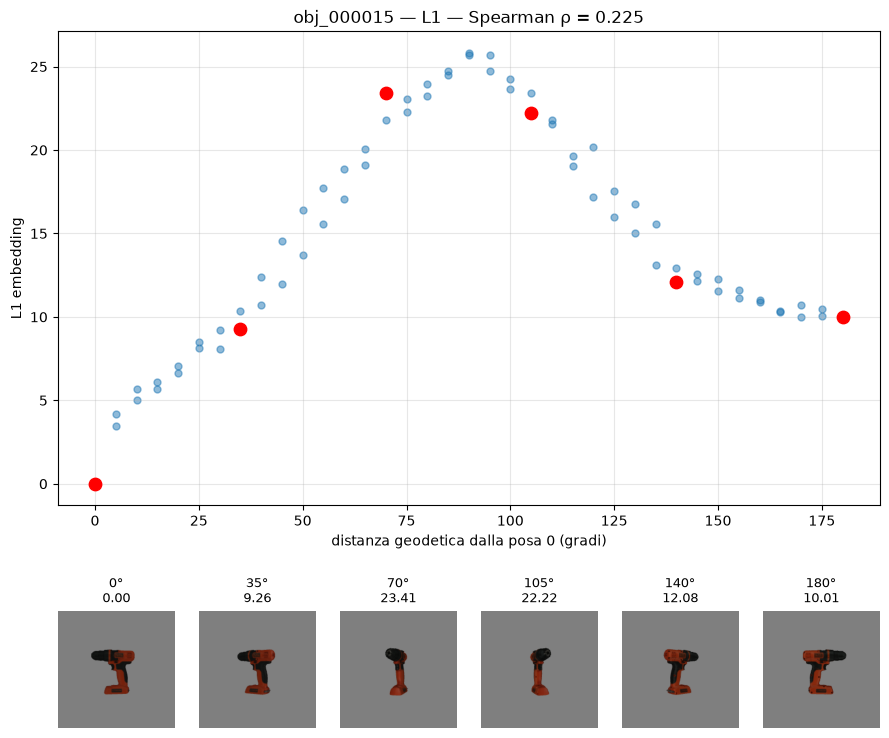

In [46]:
import pandas as pd
from scipy.spatial.transform import Rotation
from scipy.stats import spearmanr

def plot_object(obj_name, dataset="ycbv", layers=[-1], token="hybrid", metric="cos_dist"):
    # 1. leggi il CSV e filtra l'oggetto
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    assert len(df) > 0, f"nessuna riga per {obj_name}"

    # 2. ricostruisci le rotazioni
    r_cols = [f"r{a}{b}" for a in range(3) for b in range(3)]
    R_all = Rotation.from_matrix(df[r_cols].values.reshape(-1, 3, 3))

    # 3. riferimento = prima riga
    R_ref = R_all[0]
    e_ref = extract_features2(Image.open(RENDERS / df.loc[0, "image"]).convert("RGB"),
                             layers=layers, token=token)

    # 4. angoli + distanza (secondo la metrica scelta)
    angles, dists = [], []
    for i in range(len(df)):
        ang = (R_ref.inv() * R_all[i]).magnitude() * 180 / np.pi
        e = extract_features2(Image.open(RENDERS / df.loc[i, "image"]).convert("RGB"),
                             layers=layers, token=token)
        if metric == "cos_dist":
            d = 1.0 - F.cosine_similarity(e_ref, e, dim=0).item()
        elif metric == "L2":
            d = torch.norm(e_ref - e).item()
        elif metric == "L1":
            d = torch.abs(e_ref - e).sum().item()
        else:
            raise ValueError(metric)
        dists.append(d)
        angles.append(ang)
    angles, dists = np.array(angles), np.array(dists)
    rho, _ = spearmanr(angles, dists)

    # 6 viste equispaziate lungo l'asse degli angoli
    order = np.argsort(angles)
    sel = order[np.linspace(0, len(order) - 1, 6).astype(int)]

    # --- figura: scatter sopra + 6 viste sotto ---
    fig, axes = plt.subplots(2, 1, figsize=(9, 8),
                             gridspec_kw={"height_ratios": [3, 1.4]})
    axes[0].scatter(angles, dists, s=25, alpha=0.5)
    axes[0].scatter(angles[sel], dists[sel], s=80, color="red", zorder=5)
    axes[0].set_xlabel("distanza geodetica dalla posa 0 (gradi)")
    axes[0].set_ylabel(f"{metric} embedding")
    axes[0].set_title(f"{obj_name} — {metric} — Spearman ρ = {rho:.3f}")
    axes[0].grid(alpha=0.3)

    gs = axes[1].get_subplotspec().subgridspec(1, 6)
    axes[1].remove()
    for k, idx in enumerate(sel):
        ax = fig.add_subplot(gs[0, k])
        ax.imshow(Image.open(RENDERS / df.loc[idx, "image"]).convert("RGB"))
        ax.set_title(f"{angles[idx]:.0f}°\n{dists[idx]:.2f}", fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


OBJECTS = ["obj_000001", "obj_000002", "obj_000003", "obj_000015"]
for obj in OBJECTS:
    plot_object(obj, metric="L1")     

# PROVA CON ROTAZIONI SU TUTTI GLI ASSI

GENERATO 400 rotazioni su tutti gli assi e prendo solo quelle dopo i 90 gradi 

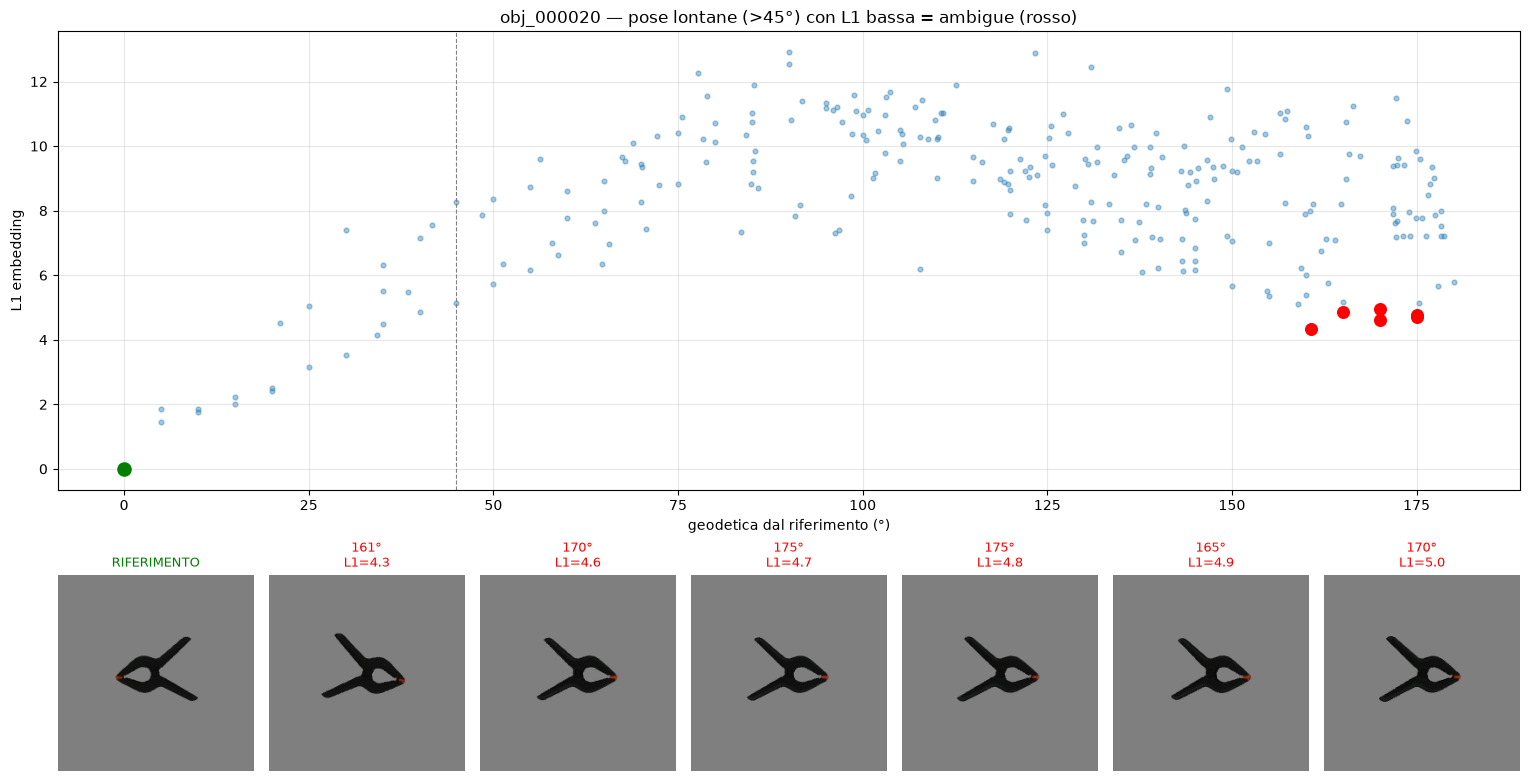

In [55]:
def scatter_plus_ambigue(obj_name, ref_idx=0, dataset="ycbv", grid=2,
                         min_angle=90, n_show=6):
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    r_cols = [f"r{a}{b}" for a in range(3) for b in range(3)]
    R_all = Rotation.from_matrix(df[r_cols].values.reshape(-1, 3, 3))

    e_ref = extract_features2(Image.open(RENDERS / df.loc[ref_idx,"image"]).convert("RGB"),
                              token="pool", grid=grid)
    geo, l1 = [], []
    for i in range(len(df)):
        geo.append((R_all[ref_idx].inv() * R_all[i]).magnitude() * 180/np.pi)
        e = extract_features2(Image.open(RENDERS / df.loc[i,"image"]).convert("RGB"),
                              token="pool", grid=grid)
        l1.append(torch.abs(e_ref - e).sum().item())
    geo, l1 = np.array(geo), np.array(l1)

    # pose lontane (>min_angle) ma con L1 piu' bassa = ambigue
    far = np.where(geo > min_angle)[0]
    sel = far[np.argsort(l1[far])][:n_show]

    # --- figura: scatter sopra + immagini sotto ---
    fig = plt.figure(figsize=(2.2*(n_show+1), 8))
    gs = fig.add_gridspec(2, n_show+1, height_ratios=[3, 1.4])

    # scatter (occupa tutta la riga alta)
    ax = fig.add_subplot(gs[0, :])
    ax.scatter(geo, l1, s=12, alpha=0.4)
    ax.scatter(geo[sel], l1[sel], s=70, color="red", zorder=5)   # le ambigue
    ax.scatter(geo[ref_idx], l1[ref_idx], s=90, color="green", zorder=5)  # il riferimento
    ax.axvline(min_angle, ls="--", c="gray", lw=0.8)
    ax.set_xlabel("geodetica dal riferimento (°)")
    ax.set_ylabel("L1 embedding")
    ax.set_title(f"{obj_name} — pose lontane (>{min_angle}°) con L1 bassa = ambigue (rosso)")
    ax.grid(alpha=0.3)

    # immagini sotto: riferimento (verde) + le ambigue (rosse)
    ax0 = fig.add_subplot(gs[1, 0])
    ax0.imshow(Image.open(RENDERS / df.loc[ref_idx,"image"]).convert("RGB"))
    ax0.set_title("RIFERIMENTO", fontsize=9, color="green"); ax0.axis("off")
    for k, idx in enumerate(sel):
        axk = fig.add_subplot(gs[1, k+1])
        axk.imshow(Image.open(RENDERS / df.loc[idx,"image"]).convert("RGB"))
        axk.set_title(f"{geo[idx]:.0f}°\nL1={l1[idx]:.1f}", fontsize=9, color="red")
        axk.axis("off")

    plt.tight_layout()
    plt.show()


scatter_plus_ambigue("obj_000020", ref_idx=0, min_angle=45, n_show=6)

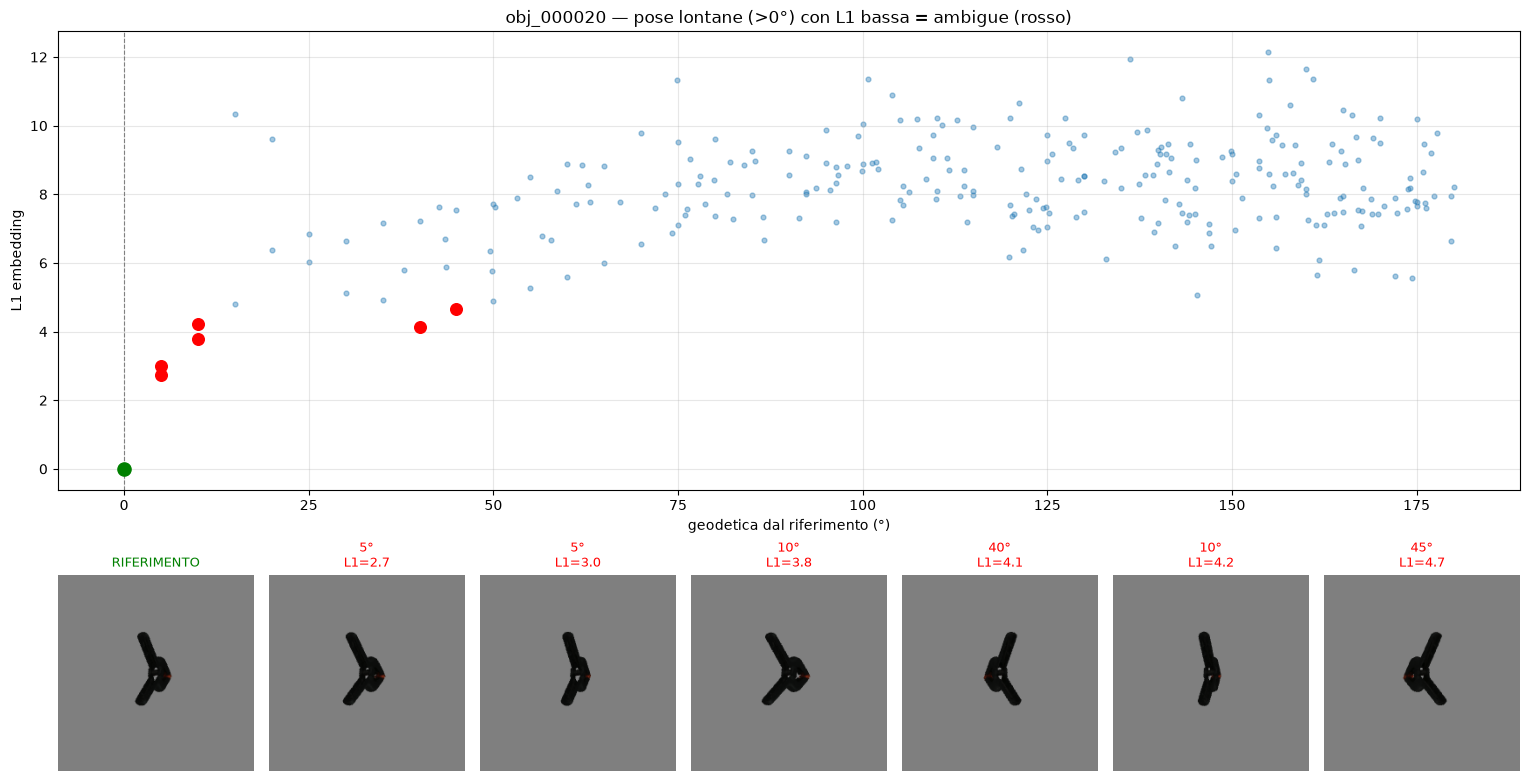

In [48]:
scatter_plus_ambigue("obj_000020", ref_idx=50, min_angle=0, n_show=6)

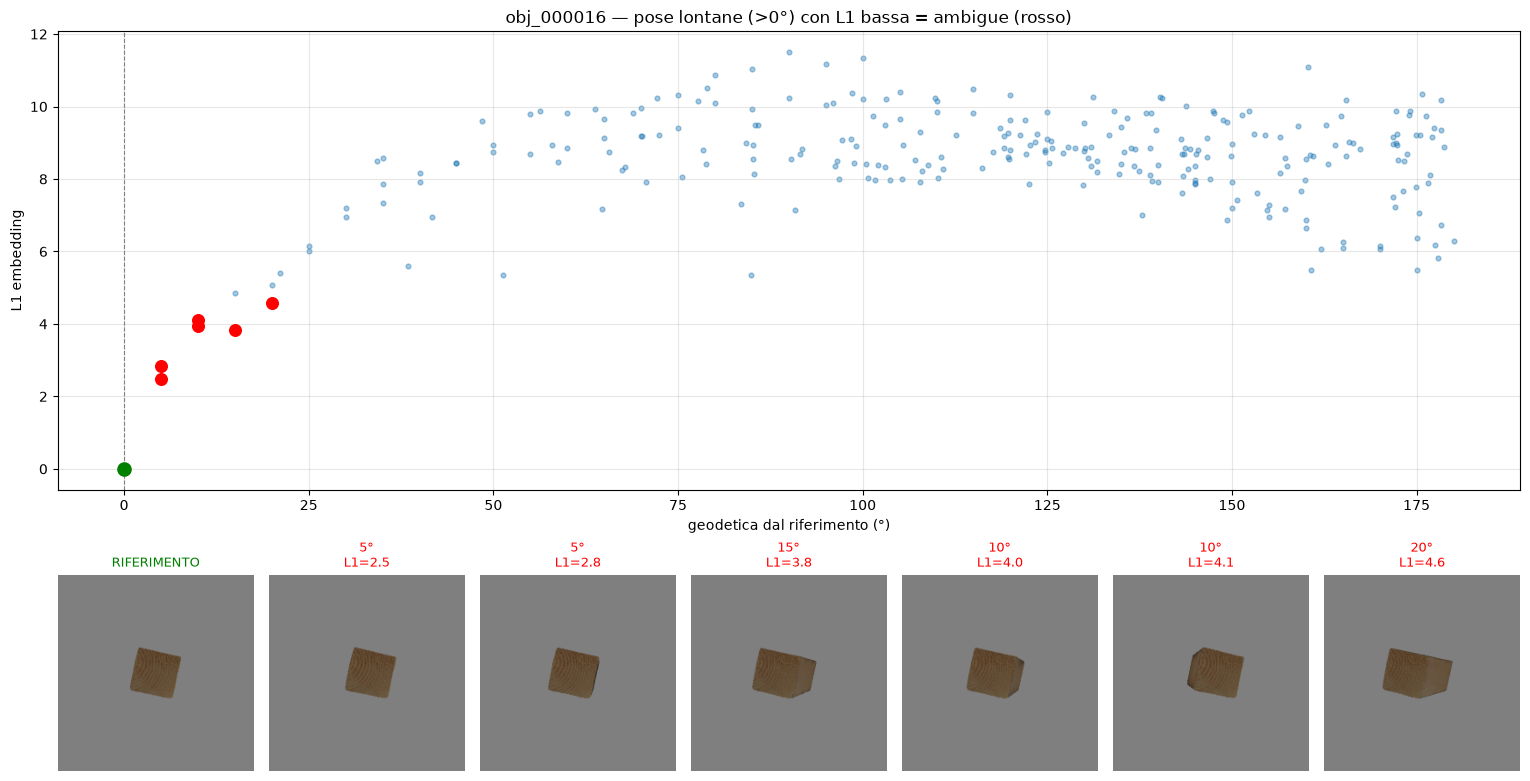

In [49]:
scatter_plus_ambigue("obj_000016", ref_idx=0, min_angle=0, n_show=6)

# PROVA CON TRANSLAZIONI


Cosa cambia invece sulla translazione tra patch e class token????

In [56]:
def sensitivity_trans(obj_name, dataset="ycbv_translation", token="pool", grid=2,
                      component="all"):
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    T_all = df[["tx", "ty", "tz"]].values
    t_ref = T_all[0]

    e_ref = extract_features2(Image.open(RENDERS / df.loc[0,"image"]).convert("RGB"),
                              token=token, grid=grid)
    tdist, dists = [], []
    for i in range(len(df)):
        dt = T_all[i] - t_ref
        if component == "inplane":
            x = np.linalg.norm(dt[:2])          # solo tx, ty
        elif component == "depth":
            x = abs(dt[2])                      # solo tz
        else:
            x = np.linalg.norm(dt)              # tutte e tre
        tdist.append(x)
        e = extract_features2(Image.open(RENDERS / df.loc[i,"image"]).convert("RGB"),
                              token=token, grid=grid)
        dists.append(torch.abs(e_ref - e).sum().item())
    return np.array(tdist), np.array(dists)


# Analisi per il dataset In-Plane
td_inplane, d_inplane = sensitivity_trans("obj_000015", dataset="ycbv_inplane", token="pool")
print(f"Sensibilità IN-PLANE pool: rho = {spearmanr(td_inplane, d_inplane).statistic:.3f}")

td_inplane, d_inplane = sensitivity_trans("obj_000015", dataset="ycbv_inplane", token="cls")
print(f"Sensibilità IN-PLANE cls: rho = {spearmanr(td_inplane, d_inplane).statistic:.3f}")

# Analisi per il dataset Depth
td_depth, d_depth = sensitivity_trans("obj_000015", dataset="ycbv_inplane", token="hybrid")
print(f"Sensibilità IN-PLANE hyb: rho = {spearmanr(td_depth, d_depth).statistic:.3f}")


# Analisi per il dataset Depth
td_depth, d_depth = sensitivity_trans("obj_000015", dataset="ycbv_offplane", token="pool")
print(f"Sensibilità DEPTH pool: rho = {spearmanr(td_depth, d_depth).statistic:.3f}")

td_depth, d_depth = sensitivity_trans("obj_000015", dataset="ycbv_offplane", token="cls")
print(f"Sensibilità DEPTH cls: rho = {spearmanr(td_depth, d_depth).statistic:.3f}")


td_depth, d_depth = sensitivity_trans("obj_000015", dataset="ycbv_offplane", token="hybrid")
print(f"Sensibilità DEPTH hyb: rho = {spearmanr(td_depth, d_depth).statistic:.3f}")

Sensibilità IN-PLANE pool: rho = 0.943
Sensibilità IN-PLANE cls: rho = 0.104
Sensibilità IN-PLANE hyb: rho = 0.803
Sensibilità DEPTH pool: rho = 0.972
Sensibilità DEPTH cls: rho = 0.847
Sensibilità DEPTH hyb: rho = 0.939


Sembra che cls si migliore nella depth (ha senso vede l'oggetto nella sua interezza) patch sono piu bravi nelle translazione, 

Invece se cambio la griglia???? 

In [51]:
for gr in [2, 4, 8]:
    td, d = sensitivity_trans("obj_000015", dataset="ycbv_offplane", token="pool", grid=gr)
    print(f"grid {gr} inplane: rho = {spearmanr(td,d).statistic:.3f}")

grid 2 inplane: rho = 0.972
grid 4 inplane: rho = 0.993
grid 8 inplane: rho = 0.994


Test solamente di pool con griglia diversa, tra depth e inplane (Oppure usare HYBRID APPROACH????)

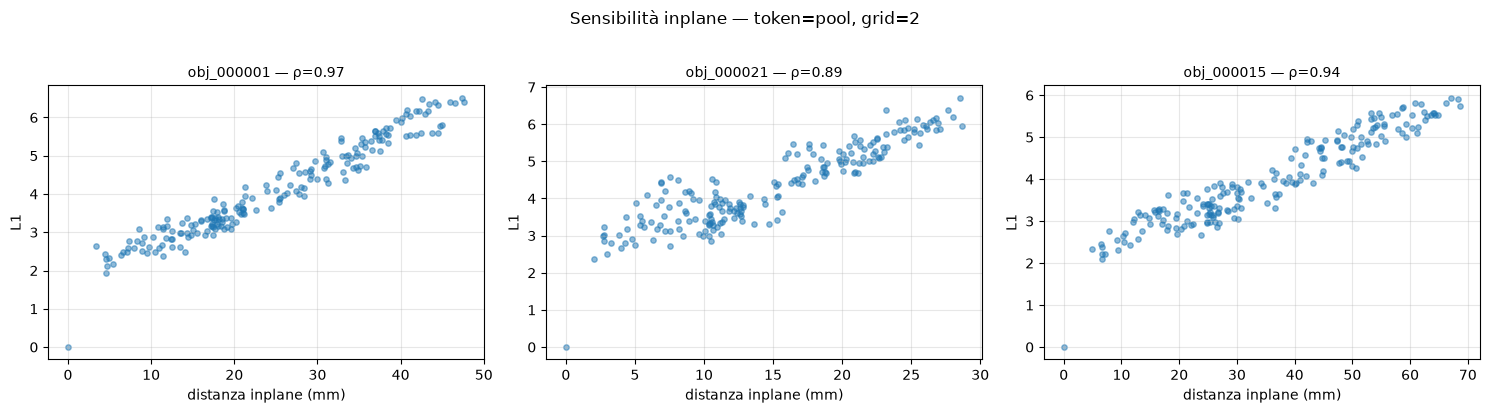

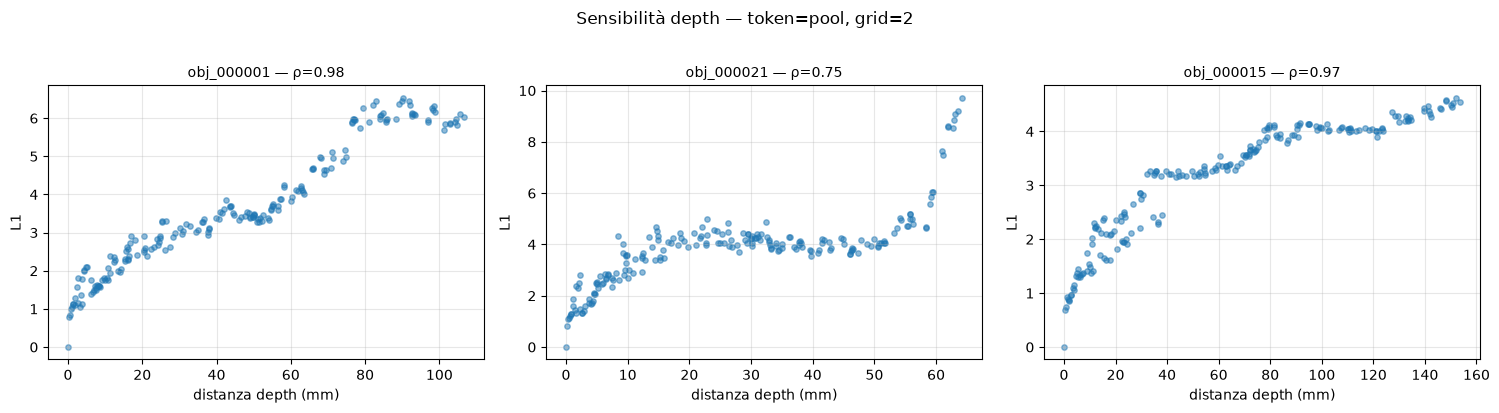

In [52]:
def plot_trans_objects(objects, dataset="ycbv_translation", token="pool", grid=4,
                       component="all", n_cols=3):
    n_rows = int(np.ceil(len(objects)/n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows))
    axes = np.atleast_1d(axes).flatten()
    for ax, obj in zip(axes, objects):
        td, d = sensitivity_trans(obj, dataset=dataset, token=token,
                                  grid=grid, component=component)
        rho = spearmanr(td, d).statistic
        ax.scatter(td, d, s=15, alpha=0.5)
        ax.set_title(f"{obj} — ρ={rho:.2f}", fontsize=10)
        ax.set_xlabel(f"distanza {component} (mm)"); ax.set_ylabel("L1")
        ax.grid(alpha=0.3)
    for ax in axes[len(objects):]:
        ax.axis("off")
    plt.suptitle(f"Sensibilità {component} — token={token}, grid={grid}", y=1.02)
    plt.tight_layout(); plt.show()

OBJECTS = ["obj_000001", "obj_000021", "obj_000015"]
plot_trans_objects(OBJECTS, dataset="ycbv_inplane", component="inplane", grid=2)
OBJECTS = ["obj_000001", "obj_000021", "obj_000015"]
plot_trans_objects(OBJECTS, dataset="ycbv_offplane", component="depth", grid=2)

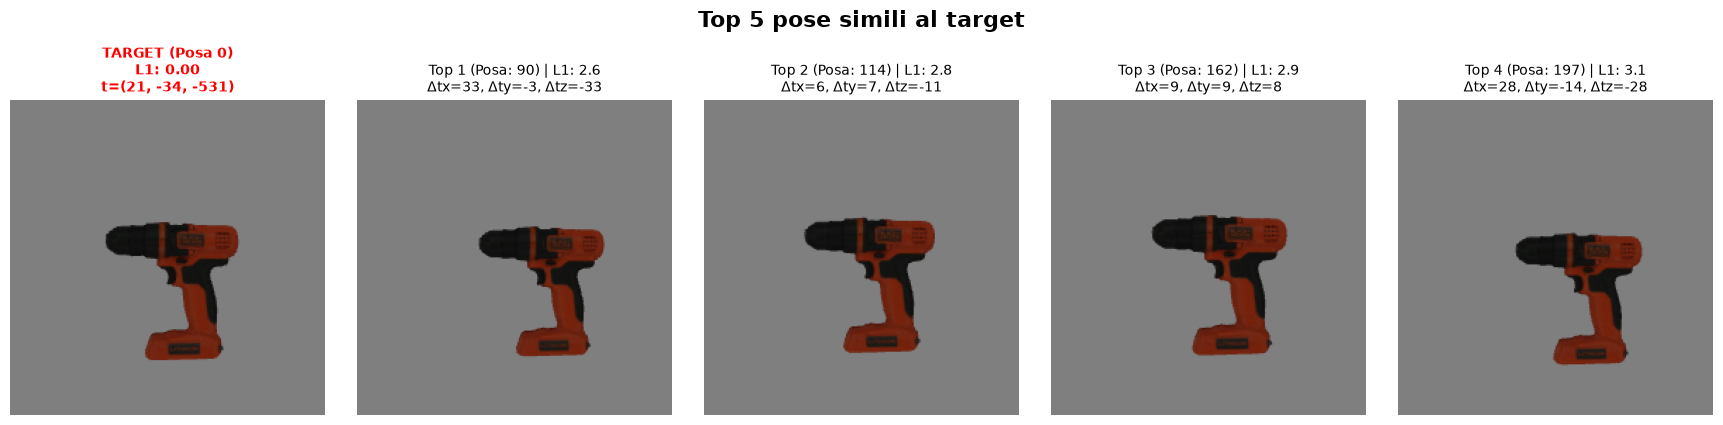

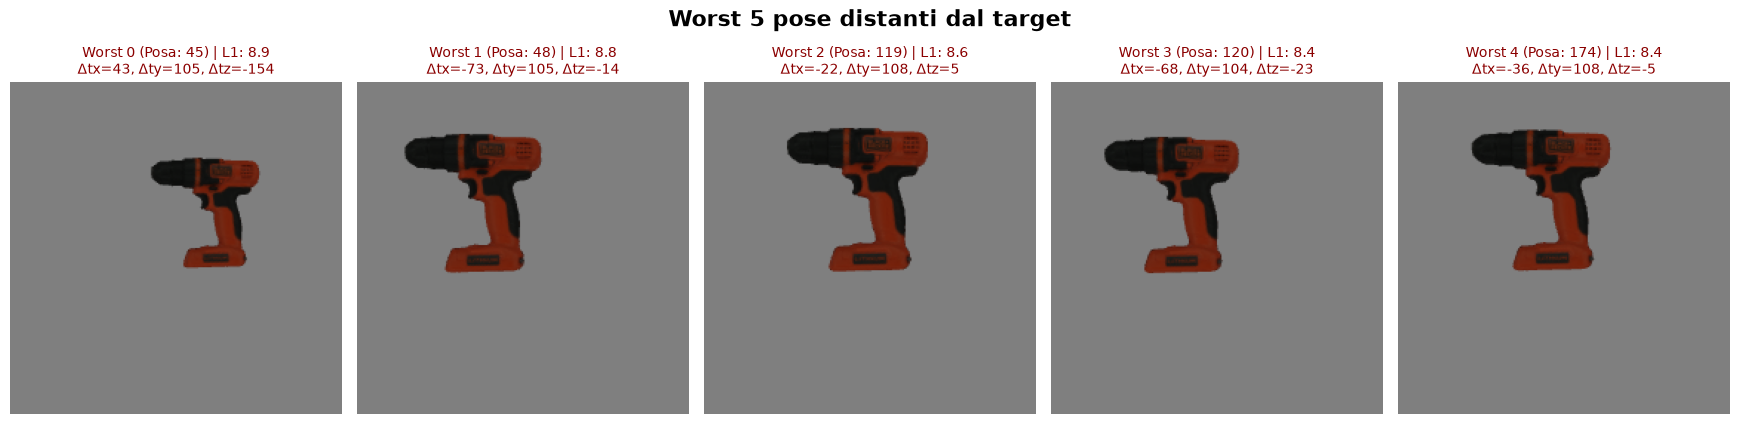

In [53]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt

def visualizza_embedding_3d_plotly(obj_name, dataset="ycbv_translation", token="pool", grid=2, K=10, W=5):
    df = pd.read_csv(RENDERS / dataset / "gt_poses.csv")
    df = df[df["object"] == obj_name].reset_index(drop=True)
    T = df[["tx", "ty", "tz"]].values 

    img_paths = [RENDERS / img_path for img_path in df["image"]]

    # embedding di riferimento + L1 di ogni posa
    e_ref = extract_features2(Image.open(img_paths[0]).convert("RGB"),
                              token=token, grid=grid)
    L1 = []
    for i in range(len(df)):
        e = extract_features2(Image.open(img_paths[i]).convert("RGB"),
                              token=token, grid=grid)
        L1.append(torch.abs(e_ref - e).sum().item())
    L1 = np.array(L1)

    indici_ordinati = np.argsort(L1)
    indici_top_k = indici_ordinati[:K]
    indici_worst_w = indici_ordinati[-W:][::-1] 
    
    t_ref = T[0]

    custom_colors = [
        [0.0, "red"], 
        [0.3, "yellow"], 
        [1.0, "blue"]
    ]
    
    fig = go.Figure()

    fig.add_trace(go.Scatter3d(
        x=T[:, 0], y=T[:, 1], z=T[:, 2],
        mode='markers',
        marker=dict(
            size=6, color=L1, colorscale=custom_colors,
            colorbar=dict(title="L1", thickness=20),
            opacity=0.7
        ),
        text=[f"Posa: {i}<br>L1: {val:.2f}" for i, val in enumerate(L1)],
        hoverinfo='text+x+y+z',
        name="Tutte le pose"
    ))

    fig.add_trace(go.Scatter3d(
        x=T[indici_top_k, 0], y=T[indici_top_k, 1], z=T[indici_top_k, 2],
        mode='markers',
        marker=dict(
            size=10, color='rgba(0,0,0,0)', line=dict(color='white', width=3) 
        ),
        text=[f"Top {i}<br>Posa: {idx}" for i, idx in enumerate(indici_top_k)],
        hoverinfo='text',
        name=f"Top {K}"
    ))

    fig.add_trace(go.Scatter3d(
        x=T[indici_worst_w, 0], y=T[indici_worst_w, 1], z=T[indici_worst_w, 2],
        mode='markers',
        marker=dict(
            size=10, color='rgba(0,0,0,0)', line=dict(color='black', width=3) 
        ),
        text=[f"Worst {i}<br>Posa: {idx}" for i, idx in enumerate(indici_worst_w)],
        hoverinfo='text',
        name=f"Worst {W}"
    ))

    fig.update_layout(
        title=f"Spazio Pose 3D ({len(df)} punti) — {obj_name}",
        scene=dict(
            xaxis=dict(title='tx (mm)'), yaxis=dict(title='ty (mm)'), zaxis=dict(title='tz (mm)'),
            aspectmode='data'
        ),
        margin=dict(l=0, r=0, b=0, t=40)
    )
    
    fig.show()

    def disegna_griglia(indici, titolo_griglia, is_worst=False):
        n_img = len(indici)
        cols = 5 
        rows = (n_img + cols - 1) // cols 
        
        fig_mat, axes = plt.subplots(rows, cols, figsize=(cols * 3.5, rows * 4))
        fig_mat.suptitle(titolo_griglia, fontsize=16, fontweight='bold', y=1.05)
        
        if n_img > 1: 
            axes = np.array(axes).flatten()
        else: 
            axes = [axes]
            
        for ax_idx, orig_idx in enumerate(indici):
            img = Image.open(img_paths[orig_idx])
            axes[ax_idx].imshow(img)
            axes[ax_idx].axis('off') 
            
            t_corrente = T[orig_idx]
            delta_t = t_corrente - t_ref
            
            if orig_idx == 0:
                titolo = f"TARGET (Posa 0)\nL1: 0.00\nt=({t_ref[0]:.0f}, {t_ref[1]:.0f}, {t_ref[2]:.0f})"
                axes[ax_idx].set_title(titolo, color="red", fontweight="bold", fontsize=10)
            else:
                label_prefisso = "Worst" if is_worst else "Top"
                colore_testo = "black" if not is_worst else "darkred"
                titolo = (f"{label_prefisso} {ax_idx} (Posa: {orig_idx}) | L1: {L1[orig_idx]:.1f}\n"
                          f"Δtx={delta_t[0]:.0f}, Δty={delta_t[1]:.0f}, Δtz={delta_t[2]:.0f}")
                axes[ax_idx].set_title(titolo, fontsize=10, color=colore_testo)
                
        for ax_idx in range(n_img, len(axes)):
            axes[ax_idx].axis('off')

        plt.tight_layout()
        plt.show()

    disegna_griglia(indici_top_k, f"Top {K} pose simili al target")
    disegna_griglia(indici_worst_w, f"Worst {W} pose distanti dal target", is_worst=True)

visualizza_embedding_3d_plotly("obj_000015", grid=2, K=5, W=5)